# Running on Empty: When and Where Does Bluebikes Run Out of Bikes and Docks?

**BA780 Final Project Deliverable, Cohort B, Team 10 (B10)**  
**Members:** Adham (PM), Mia, Daniel, Grace, Eldo  
**Due:** Monday, Oct 19, 2026

The saved outputs were generated by running this notebook from the beginning in Google Colab, using the 31 logger files through October 17, 2026

## **Data sources**
1. Bluebikes trip history, Sept 2025 to Aug 2026
    - ~4.6M rows x 13 columns (190 MB zipped)
    - Source: [S3 bucket](https://s3.amazonaws.com/hubway-data/index.html) with the 2025-2026 files unzipped to data/bluebikes-trips/
    - LICENSE: [Bluebikes Data License Agreement](https://bluebikes.com/data-license-agreement)
2. Bluebikes station list (Aug 2026)
    - 600 rows x 5 columns (a few KB)
    - Source: [bluebikes.com/system-data](https://bluebikes.com/system-data) saved as data/Bluebike Stations.csv
    - LICENSE: [Bluebikes Data License Agreement](https://bluebikes.com/data-license-agreement)
3. GBFS station availability, logged by our team every ~10 min since Sept 17
    - 70k rows/day x 13 columns (5 MB/day)
    - source: Logged by our own GitHub Actions cron ([AdhamKhouly/bluebikes-logger](https://github.com/AdhamKhouly/bluebikes-logger)), synced to data/gbfs-logs/ and collected from https://gbfs.bluebikes.com/gbfs/gbfs.json with station information collected from https://gbfs.bluebikes.com/gbfs/en/station_information.json programmatically
    - LICENSE: [Bluebikes Data License Agreement](https://bluebikes.com/data-license-agreement)
4. NOAA daily weather, Boston Logan (GHCND station `USW00014739`)
    - 51k rows x 12 columns (~5.1mb)
    - Source: [NOAA Climate Data Online](https://www.ncei.noaa.gov/cdo-web/) (Daily Summaries), saved as `data/NOAA daily weather, Boston Logan.csv`
    - LICENSE: U.S. Government work, public domain

## Google Drive Project Folder Skeleton

```text
BA780-bluebikes/
├── B10-Running-On-Empty.ipynb
├── data/
│   ├── Bluebike Stations.csv
│   ├── NOAA daily weather, Boston Logan.csv
│   ├── bluebikes-trips/
│   │   ├── 202509-bluebikes-tripdata.csv
│   │   ├── ...
│   │   └── 202608-bluebikes-tripdata.csv
│   └── gbfs-logs/
│       ├── station_status_2026-09-17.csv
│       └── ...
├── notebooks/
└── outputs/
```

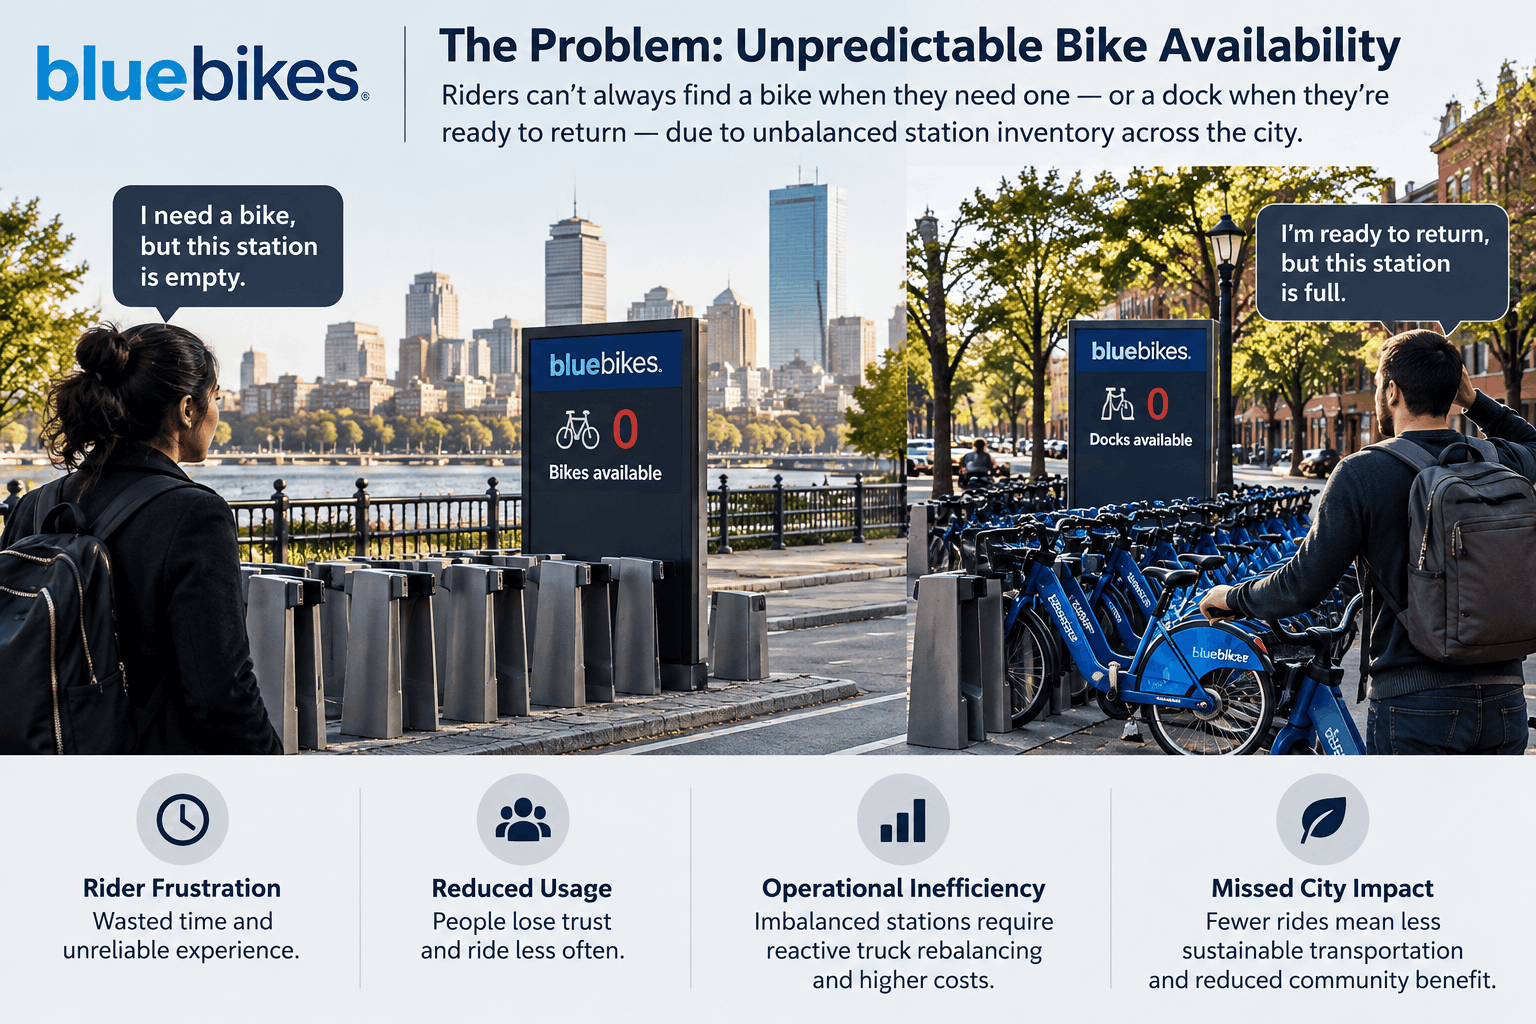

## Executive Summary

*Objective.* Bluebikes riders regularly find stations with no bikes or no open docks. We set out to identify when and where these shortages happen, whether they can be predicted, and which stations the rebalancing team should prioritize.

*Methods.* We combined a year of trip records (4.6 million trips, Sep 2025 to Aug 2026), the station list and NOAA weather with our own log of the live station feed (Sep 16 to Oct 19, 2026; 13 days at 10-minute resolution). We ranked stations and station-hours by shortage rate and tested the rankings on held-out days.

*Key findings.* Shortages are concentrated: the 20 worst stations produce 18.9% of all empty readings, led by office and campus stations in Kendall and downtown. The pressure map is stable. The same morning drainers top the list in both halves of the year (18 of 20, r = 0.97), and rain shrinks the drain by about 20% without changing which stations drain. Live shortage rates also carry forward: the 20 stations flagged in training were empty 23.6% of the time on the test days, against 5.0% for the rest. Trip history alone is not enough. The biggest drainers are empty 1.7 times as often as average, but trip volume barely ranks stations by how often they actually run out (rank correlation −0.17), because vans already make an estimated 98 refills a day.

*Recommendations.* Bluebikes should add a weekday evening delivery loop through Kendall, MIT and Longwood from 5 pm, starting with Ames St at Main St (empty 56% of the time at 6 pm). It should also clear docks at Kendall and MIT stations in the 8 to 9 am rush, run short morning shuttles between paired drainer and filler stations (median 0.85 km apart), and refresh the priority list weekly from the live feed. The next step is to pilot the evening loop and measure whether shortages fall.

## 1. Introduction and motivation

Every Bluebikes user faces two problems with this system:
1. You show up and there are no bikes.
2. You arrive and there is nowhere to put one.

Bluebikes is transit infrastructure for 13 municipalities with about 4.6 million rides last year. The company already pays people to drive vans around all day moving bikes between stations, so the question is not whether to move bikes. It is whether anyone can know, ahead of time, where the trouble will be. We think the answer is in a year of trip records and in our own log of the live station feed.

### Approach

Our goal is to help Bluebikes decide **where and when to rebalance bikes** to reduce station shortages.

We analyze one year of historical trips alongside live station availability data collected every 10 minutes. Trip data reveals when and where bikes move, while the live data shows when stations actually run out of bikes or available docks.

Our analysis answers three questions:

1. **Where and when do shortages occur?**
2. **Can historical trip patterns help anticipate these shortages?**
3. **Which stations and hours should Bluebikes prioritize for rebalancing?**

We use pandas, descriptive statistics, correlations, and comparisons across time periods. No machine learning models are used.

Our primary audience is the Bluebikes/Lyft operations team, with riders and participating municipalities as additional stakeholders.

### Success Metrics

We evaluate our findings using five criteria:

| Metric | Success criteria |
|---|---|
| **M1. Consistency** | Historical patterns remain stable across the year (≥15 overlapping top-20 stations; correlation ≥0.8). |
| **M2. Real-world agreement** | Historical patterns align with observed shortages (≥1.5× average empty rate; Spearman ≤−0.3). |
| **M3. Predictability** | Shortage rankings remain useful across different days (Spearman ≥0.5; flagged stations ≥3× empty rate). |
| **M4. Data coverage** | At least five days with ≥36 snapshots, covering all weekday and weekend hours. |
| **M5. Actionability** | Identify 40 priority station-hours across ≤30 stations, with median rebalancing pairing distance below 1.5 km. |

These are our proposed targets, informed by the Team Assignment feedback. We assess them in Section 6.

**Limitation:** We can identify promising rebalancing opportunities, but measuring whether they actually reduce shortages would require implementing and testing our recommendations.

### Data Dictionary

The tables below describe the main columns used in our analysis, including fields created during cleaning and analysis (marked *derived*).

#### Trip history
`bluebikes-trips/*.csv`, one row per trip.

| Column | Description |
|---|---|
| `ride_id` | Unique trip identifier, used to remove duplicates |
| `rideable_type` | Classic or electric bike |
| `started_at`, `ended_at` | Trip start and end times |
| `start_station_name`, `end_station_name` | Departure and arrival station names |
| `start_station_id`, `end_station_id` | Station IDs; do not match the station list IDs |
| `member_casual` | Member or casual rider |
| `duration` *(derived)* | Trip duration in minutes |
| `hour`, `day_of_week`, `is_weekend`, `month`, `date` *(derived)* | Time variables extracted from `started_at` |
| `start_key`, `end_key` *(derived)* | Standardized station names used to match the station list |
| `stations_in_list` *(derived)* | Whether both stations were found in the station list |

#### Station list
`Bluebike Stations.csv`, one row per station, August 2026.

| Column | Description |
|---|---|
| `station_name` | Station name (originally `Name`) |
| `lat`, `lng` | Station coordinates in degrees |
| `seasonal_status` | Year Round or Winter Storage |
| `municipality` | City or town |
| `capacity` | Total number of docks |
| `legacy_id` | Older station ID; missing for 186 newer stations, so not used for matching |
| `name_key` *(derived)* | Standardized station name used to match trip records |

#### GBFS station status log
`gbfs-logs/station_status_YYYY-MM-DD.csv`, one row per station per snapshot.

| Column | Description |
|---|---|
| `snapshot_utc` | Time of the feed update (UTC) |
| `fetched_utc` | Time our logger collected the data (UTC) |
| `station_id` | GBFS station identifier |
| `num_bikes_available` | Bikes available to rent |
| `num_docks_available` | Open docks available |
| `is_installed`, `is_renting`, `is_returning` | Station operating status |
| `snapshot` *(derived)* | Snapshot time converted to Boston time |
| `is_empty`, `is_full` *(derived)* | Whether a station has no available bikes or docks while operating |
| `date`, `hour`, `is_weekend`, `day_name` *(derived)* | Time variables extracted from `snapshot` |
| `name`, `short_name`, `capacity` *(merged)* | Station details from the GBFS information feed |
| `name_key` *(derived)* | Standardized station name used to match trip data |

#### NOAA daily weather
`NOAA daily weather, Boston Logan.csv`, one row per day (Boston Logan only).

| Column | Description |
|---|---|
| `STATION`, `NAME` | Weather station identifier and name; filtered to Boston Logan |
| `DATE` | Observation date |
| `TMAX`, `TMIN` | Daily high and low temperatures (°F) |
| `PRCP`, `SNOW` | Daily precipitation and snowfall (inches) |
| `AWND` | Average wind speed (mph) |
| `daily_trips` *(derived)* | Number of trips started that day |
| `conditions` *(derived)* | Wet if precipitation is greater than zero |
| `temp_band` *(derived)* | Maximum temperature grouped into 10°F bands |

#### Tables created during analysis

| Table | Purpose |
|---|---|
| `flow` | Weekday station-hour departures, arrivals, net flow, and flow per day/dock |
| `sh` | Daily station-hour flows used to compare the two halves of the year |
| `am_drain` | Average net bike change per station in the weekday morning rush (7 to 9 am) |
| `dense`, `wd_dense` | Live-feed readings from the dense logging period, including a weekday subset |
| `station_rates` | Empty and full rates for each station |
| `val12` | Comparison of historical morning net flow with observed empty rates |
| `persist`, `sh_split` | Earlier versus later empty rates, by station and station-hour |
| `flow14`, `priority` | Station-hour shortages and estimated riders affected, used for prioritization |
| `pairs_df` | Recommended drainer to filler station pairs and distances (km) |

**Note:** Net flow is calculated as arrivals minus departures. Negative values indicate stations losing bikes, while positive values indicate stations gaining bikes. Empty and full rates represent the proportion of station readings with no available bikes or docks, respectively.

## Setup

In [1]:
# Libraries and Google Drive
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')
DATA = "/content/drive/MyDrive/BA780-bluebikes/data"
OUT = "/content/drive/MyDrive/BA780-bluebikes/outputs"   # the Q14 priority table is saved here

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Data loading and cleaning (condensed from the Team Assignment)

The cleaning steps from the Team Assignment are kept here with their before and after counts. Each dataset ends with a short takeaway.

### 2.1 Trip history (Mia and Eldo)

In [2]:
# Load the 12 monthly trip files and combine them into one table
folder = f"{DATA}/bluebikes-trips"
months = ["202509", "202510", "202511", "202512", "202601", "202602",
          "202603", "202604", "202605", "202606", "202607", "202608"]

monthly_frames = []
for m in months:
    monthly_frames.append(pd.read_csv(f"{folder}/{m}-bluebikes-tripdata.csv"))
trips = pd.concat(monthly_frames, ignore_index=True)

trips.info(show_counts=True)   # show_counts forces the null counts on a large table

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4605371 entries, 0 to 4605370
Data columns (total 13 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   ride_id             4605371 non-null  object 
 1   rideable_type       4605371 non-null  object 
 2   started_at          4605371 non-null  object 
 3   ended_at            4605371 non-null  object 
 4   start_station_name  4603243 non-null  object 
 5   start_station_id    4603243 non-null  object 
 6   end_station_name    4597413 non-null  object 
 7   end_station_id      4596723 non-null  object 
 8   start_lat           4605371 non-null  float64
 9   start_lng           4605371 non-null  float64
 10  end_lat             4602309 non-null  float64
 11  end_lng             4602309 non-null  float64
 12  member_casual       4605371 non-null  object 
dtypes: float64(4), object(9)
memory usage: 456.8+ MB


About 4.6 million rows and 13 columns. The timestamps loaded as text, and the station columns have fewer non-null values than the row count, so some trips have no station.

In [3]:
# Fix the data types: IDs and labels as strings, timestamps as datetime
text_cols = ["ride_id", "rideable_type", "start_station_name", "start_station_id",
             "end_station_name", "end_station_id", "member_casual"]
for col in text_cols:
    trips[col] = trips[col].astype("string")
trips["started_at"] = pd.to_datetime(trips["started_at"])
trips["ended_at"] = pd.to_datetime(trips["ended_at"])

trips.head(3)

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,141F6366FDD45720,electric_bike,2025-09-20 09:32:51.460,2025-09-20 09:35:02.699,Everett Square (Broadway at Norwood St),V32003,Swan St. Park,V32007,42.407381,-71.055356,42.412505,-71.058422,member
1,E9A55253A0B9B86B,classic_bike,2025-09-17 11:20:09.980,2025-09-17 11:41:39.436,Commonwealth Ave at Agganis Way,A32002,Nubian Square - Bolling Building,B32017,42.351692,-71.119035,42.329843,-71.083866,member
2,95834E3240C1DB01,classic_bike,2025-09-17 07:37:55.648,2025-09-17 07:42:40.162,Dudley Town Common - Mt Pleasant Ave at Blue H...,C32015,Nubian Square - Bolling Building,B32017,42.325333,-71.075354,42.329843,-71.083866,member


Trips with no start or end station are e-bikes locked outside a dock. Bluebikes also closes a trip automatically after about 25 hours, so most very long trips have no end station. We count them before dropping the trips without a station, then remove duplicate rides.

In [4]:
missing = trips[trips["start_station_id"].isna() | trips["end_station_id"].isna()]
long_missing = (missing["ended_at"] - missing["started_at"]).dt.total_seconds() / 3600 >= 24
print("\nTrips with a missing station:", len(missing), " of which 24 hours or longer:", long_missing.sum())

trips = trips.dropna(subset=["start_station_id", "end_station_id"])
print("Duplicate ride_id:", trips["ride_id"].duplicated().sum())
trips = trips.drop_duplicates(subset="ride_id", keep="first")
print("Rows after removing missing stations and duplicates:", len(trips))


Trips with a missing station: 10381  of which 24 hours or longer: 3021
Duplicate ride_id: 74
Rows after removing missing stations and duplicates: 4594916


In [5]:
# Helper columns used in every section
trips["duration"] = (trips["ended_at"] - trips["started_at"]).dt.total_seconds() / 60   # minutes
trips["hour"] = trips["started_at"].dt.hour
trips["day_of_week"] = trips["started_at"].dt.day_name()
trips["is_weekend"] = trips["started_at"].dt.dayofweek >= 5
trips["month"] = trips["started_at"].dt.to_period("M")
trips["date"] = trips["started_at"].dt.normalize()

print("Date range:", trips["started_at"].min(), "to", trips["started_at"].max())
trips["duration"].describe().round(1)

Date range: 2025-08-31 12:52:34.171000 to 2026-08-31 23:56:02.438000


,duration
count,4594916.0
mean,15.2
std,28.7
min,-58.8
25%,6.3
50%,10.5
75%,17.5
max,1498.3


The shortest trip is negative and the longest is about 25 hours. We check both.

In [6]:
# Trips that end before they start
negative_trips = trips[trips["duration"] <= 0]
print("Trips with duration <= 0:", len(negative_trips))
print("Dates:", negative_trips["started_at"].dt.date.unique())
negative_trips[["start_station_name", "end_station_name", "started_at", "ended_at", "duration"]].sort_values("duration").head(5)

Trips with duration <= 0: 51
Dates: [datetime.date(2025, 11, 2)]


,start_station_name,end_station_name,started_at,ended_at,duration
1329215,Inman Square at Springfield St.,Inman Square at Springfield St.,2025-11-02 01:59:59.081,2025-11-02 01:01:09.177,-58.831733
1265527,MIT Carleton St at Amherst St,75 Binney St,2025-11-02 01:58:55.344,2025-11-02 01:01:49.076,-57.104467
1222787,Davis Square,Davis Square,2025-11-02 01:58:21.067,2025-11-02 01:01:29.257,-56.863500
1440219,Boston Public Market - Surface Rd at Sudbury St,Seaport Blvd at Sleeper St,2025-11-02 01:58:28.324,2025-11-02 01:03:11.170,-55.285900
1277094,Dorchester Ave at Savin Hill Ave,JFK/UMass T Stop,2025-11-02 01:57:59.930,2025-11-02 01:03:29.393,-54.508950


All 51 happened around 1 am on November 2, 2025, when the clocks went back, so they are clock errors and we drop them. We also drop the few trips that started on August 31, 2025, before our study period.

In [7]:
trips = trips[trips["duration"] > 0]
print("Trips before Sep 1, 2025:", (trips["started_at"] < "2025-09-01").sum())
trips = trips[trips["started_at"] >= "2025-09-01"]

print("Rows remaining:", len(trips))
print("Date range:", trips["started_at"].min(), "to", trips["started_at"].max())
print("Share of trips by members:", round((trips["member_casual"] == "member").mean() * 100, 1), "%")
print("Median trip length:", round(trips["duration"].median(), 1), "minutes")

Trips before Sep 1, 2025: 87
Rows remaining: 4594778
Date range: 2025-09-01 00:00:02.828000 to 2026-08-31 23:56:02.438000
Share of trips by members: 70.6 %
Median trip length: 10.5 minutes


The trips of 24 hours or longer that are still in the data all ended at a real dock, so we keep them.

In [8]:
long_trips = trips[trips["duration"] >= 1440]
print("Trips of 24 hours or longer:", len(long_trips), "=", round(len(long_trips) / len(trips) * 100, 3), "% of trips")
print("Shortest:", round(long_trips["duration"].min() / 60, 1), "hours   Longest:", round(long_trips["duration"].max() / 60, 1), "hours")

Trips of 24 hours or longer: 95 = 0.002 % of trips
Shortest: 24.0 hours   Longest: 25.0 hours


**Takeaway:** We started with 4,605,371 trips and kept 4,594,778 (99.8%) after cleaning, covering September 2025 through August 2026. Most removals were trips with missing stations. We also removed duplicates, trips outside our study period, and 51 negative-duration trips, all recorded around the November 2, 2025 daylight saving time change.

We also checked the unusually long trips. Of the 3,117 trips lasting 24 hours or more, 3,021 had no end station and were already excluded. We kept 95 that ended at a real dock because they still represent departures and arrivals, which is what matters for our analysis. These make up just 0.002% of the cleaned data.

Overall, members account for 70.6% of trips, and a typical ride lasts about 10.5 minutes.

| Issue | What we did |
|---|---|
| **Missing stations** | Removed 10,381 trips that could not be assigned to stations. |
| **Duplicate rides** | Removed 74 duplicates, keeping the first record. |
| **Negative durations** | Removed 51 trips affected by the daylight saving time change. |
| **Long trips (24 hours or more)** | 3,021 removed through the missing-station check; 95 kept because they ended at a dock. |
| **Outside study period** | Removed 87 trips from August 31, 2025. |
| **Date columns** | Converted `started_at` and `ended_at` to datetime for time-based analysis. |

### 2.2 Stations (Daniel)

In [9]:
# The first line of the file is a "Last Updated" note, so we skip it
stations = pd.read_csv(f"{DATA}/Bluebike Stations.csv", skiprows=1)
stations = stations.rename(columns={
    "Name": "station_name", "Lat": "lat", "Long": "lng", "Seasonal Status": "seasonal_status",
    "Municipality": "municipality", "Total Docks": "capacity",
    "Station ID (to match to historic system data)": "legacy_id"})
stations.info()
stations.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 613 entries, 0 to 612
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   station_name     613 non-null    object 
 1   lat              613 non-null    float64
 2   lng              613 non-null    float64
 3   seasonal_status  613 non-null    object 
 4   municipality     613 non-null    object 
 5   capacity         613 non-null    int64  
 6   legacy_id        613 non-null    object 
dtypes: float64(2), int64(1), object(4)
memory usage: 33.7+ KB


,station_name,lat,lng,seasonal_status,municipality,capacity,legacy_id
0,Myrtle St at Fellsway (Rt 28),42.416235,-71.085073,Year Round,Medford,15,No ID post-March 2023
1,Webster Ave at Norfolk St,42.374606,-71.094757,Year Round,Somerville,19,No ID post-March 2023
2,Washington St at Pond Ave,42.331805,-71.113557,Year Round,Brookline,19,No ID post-March 2023


In [10]:
# 186 stations have the text "No ID post-March 2023" instead of an ID
print("Placeholder IDs:", (stations["legacy_id"] == "No ID post-March 2023").sum())
stations["legacy_id"] = stations["legacy_id"].replace("No ID post-March 2023", np.nan)
print("Duplicate station names:", stations.duplicated(subset="station_name").sum())

# Do the trip station IDs match the list? (They do not, so we match on name instead)
print("Share of trip station IDs found in the list:", trips["start_station_id"].isin(stations["legacy_id"]).mean())

Placeholder IDs: 186
Duplicate station names: 0
Share of trip station IDs found in the list: 0.0


Trip IDs look like A32002 while the list only has older numeric IDs, so we match on station name. The small helper below lowercases the names and removes extra spaces. We use it again for the live feed.

In [11]:
def norm_name(s):
    return s.str.lower().str.replace(r"\s+", " ", regex=True).str.strip()

stations["name_key"] = norm_name(stations["station_name"])
trips["start_key"] = norm_name(trips["start_station_name"])
trips["end_key"] = norm_name(trips["end_station_name"])
trips["stations_in_list"] = trips["start_key"].isin(stations["name_key"]) & trips["end_key"].isin(stations["name_key"])
print("Share of trips where both stations match:", round(trips["stations_in_list"].mean() * 100, 2), "%")

trip_names = pd.Series(pd.concat([trips["start_key"], trips["end_key"]]).unique())
print("Stations in trips:", len(trip_names), " in the list:", len(stations),
      " in trips but not in the list:", (~trip_names.isin(stations["name_key"])).sum())
unmatched = trips.loc[~trips["start_key"].isin(stations["name_key"]), "start_station_name"]
unmatched.value_counts().head(5)

Share of trips where both stations match: 98.71 %
Stations in trips: 642  in the list: 613  in trips but not in the list: 30


,count
start_station_name,
Conway Park at Central Street (Temporary Winter Location),6715
Commonwealth Ave at Griggs St,6170
Bartlett St at John Elliot Sq,2692
Mass Ave T Station,2325
St Alphonsus St at Horadan Way,2101


In [12]:
# station_lookup: station name -> capacity, location and municipality, used in every later section
station_lookup = stations.set_index("name_key")[["station_name", "capacity", "lat", "lng", "municipality", "seasonal_status"]]

print("Total docks:", stations["capacity"].sum(), "  median docks per station:", stations["capacity"].median())
print(stations["seasonal_status"].value_counts())
by_city = stations.groupby("municipality")["capacity"].agg(["count", "sum"])
by_city.columns = ["stations", "total_docks"]
by_city.sort_values("stations", ascending=False)

Total docks: 10812   median docks per station: 17.0
seasonal_status
Year Round        569
Winter Storage     44
Name: count, dtype: int64


,stations,total_docks
municipality,,
Boston,352,6547
Cambridge,96,1934
Somerville,40,712
Brookline,20,329
Medford,17,207
Salem,17,203
Everett,15,206
Newton,15,194
Arlington,11,123


**Takeaway:** The station list (613 stations, 10,812 docks, 13 municipalities) cannot be joined to the trips by ID: its ID column only links to pre-2023 data and 0% of trip IDs matched. Joining on the normalised station name matches both ends of 98.71% of trips. The other 1.29% involve 30 renamed or temporary stations (for example a winter relocation at Conway Park) and are excluded only from the station-level analysis. Boston and Cambridge hold 73% of stations and 78% of docks, and 44 stations go into winter storage.

| Issue | What we did |
|---|---|
| File header | Skipped the "Last Updated" line when loading |
| `legacy_id` | "No ID post-March 2023" for 186 stations changed to missing; not usable as a join key |
| Station IDs | Trip IDs do not match the list (0%), so trips are joined on station name |
| 30 unmatched trip stations | Flagged with `stations_in_list`; kept for totals, excluded from station-level work |

### 2.3 Weather (Grace)

The NOAA file holds many Massachusetts stations and runs from Aug 31, 2025 to Oct 12, 2026, so we first filter it to Boston Logan (`USW00014739`). One row is one day. The values are in the standard US units (degrees F, inches, mph). TAVG is empty for every Logan day, so we do not use it.

In [13]:
weather_all = pd.read_csv(f"{DATA}/NOAA daily weather, Boston Logan.csv")
print("Weather stations in the file:", weather_all["STATION"].nunique())

weather = weather_all[weather_all["STATION"] == "USW00014739"].copy()
weather["DATE"] = pd.to_datetime(weather["DATE"])
weather.info()

Weather stations in the file: 165
<class 'pandas.core.frame.DataFrame'>
Index: 407 entries, 5588 to 5994
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   STATION    407 non-null    object        
 1   NAME       407 non-null    object        
 2   LATITUDE   407 non-null    float64       
 3   LONGITUDE  407 non-null    float64       
 4   ELEVATION  407 non-null    float64       
 5   DATE       407 non-null    datetime64[ns]
 6   AWND       407 non-null    float64       
 7   PRCP       407 non-null    float64       
 8   SNOW       406 non-null    float64       
 9   TAVG       0 non-null      float64       
 10  TMAX       407 non-null    float64       
 11  TMIN       407 non-null    float64       
dtypes: datetime64[ns](1), float64(9), object(2)
memory usage: 41.3+ KB


In [14]:
# Keep the study period and check the days and values
start_date = pd.Timestamp("2025-09-01")
end_date = pd.Timestamp("2026-08-31")
weather = weather[weather["DATE"].between(start_date, end_date)].sort_values("DATE")

print("Days:", len(weather), "  duplicate dates:", weather["DATE"].duplicated().sum(),
      "  missing calendar days:", len(pd.date_range(start_date, end_date).difference(weather["DATE"])))
print("Negative PRCP or SNOW:", (weather["PRCP"] < 0).sum() + (weather["SNOW"] < 0).sum(),
      "  TMAX below TMIN:", (weather["TMAX"] < weather["TMIN"]).sum())
print("Missing values:")
print(weather[["TMAX", "TMIN", "PRCP", "SNOW", "AWND", "TAVG"]].isna().sum())

Days: 365   duplicate dates: 0   missing calendar days: 0
Negative PRCP or SNOW: 0   TMAX below TMIN: 0
Missing values:
TMAX      0
TMIN      0
PRCP      0
SNOW      0
AWND      0
TAVG    365
dtype: int64


In [15]:
# Trips per day joined to the weather of that day
daily_counts = trips.groupby("date").size().rename("daily_trips").reset_index()
daily_weather = daily_counts.merge(weather, left_on="date", right_on="DATE", how="left", validate="one_to_one")

print("Days:", len(daily_weather), "  days without weather:", daily_weather["TMAX"].isna().sum())
daily_weather[["date", "daily_trips", "TMAX", "TMIN", "PRCP", "SNOW", "AWND"]].head(3)

Days: 365   days without weather: 0


,date,daily_trips,TMAX,TMIN,PRCP,SNOW,AWND
0,2025-09-01,16512,73.0,60.0,0.0,0.0,6.26
1,2025-09-02,20584,74.0,60.0,0.0,0.0,8.05
2,2025-09-03,21781,76.0,58.0,0.0,0.0,9.40


**Takeaway:** Boston Logan has one complete weather record for each of the 365 study days, with no duplicates and one missing snowfall value, which we leave missing. The `daily_weather` table joins each day's trip count to its weather and is used in Q3 and Q7.

### 2.4 GBFS availability logs (Adham)

The cell below copies the latest daily CSVs from the logger repository into Drive. It pulls whatever the logger has produced by the time it runs, so the counts it prints can be higher than the 31 files our written results are based on. If `data/gbfs-logs/` is already up to date, this cell can be skipped.

In [16]:
#made by Claude: shallow-clone the logger repo and copy every GBFS log file into our Google Drive data folder
import shutil, subprocess
from pathlib import Path
DEST = Path(f"{DATA}/gbfs-logs")
REPO = "https://github.com/AdhamKhouly/bluebikes-logger.git"
TMP  = Path("/content/_bluebikes_logger")
shutil.rmtree(TMP, ignore_errors=True)
subprocess.run(["git", "clone", "--depth", "1", "--quiet", REPO, str(TMP)], check=True)
shutil.rmtree(DEST, ignore_errors=True)
shutil.copytree(TMP / "data", DEST)
shutil.rmtree(TMP, ignore_errors=True)
files = sorted(p for p in DEST.rglob("*") if p.is_file())
print("copied", len(files), "files to", DEST)
if len(files) > 0:
    print("first:", files[0].name, "  last:", files[-1].name)

copied 33 files to /content/drive/MyDrive/BA780-bluebikes/data/gbfs-logs
first: station_status_2026-09-17.csv   last: station_status_2026-10-19.csv


In [17]:
# Read the logger files through October 17, 2026
import glob

files = sorted(glob.glob(f"{DATA}/gbfs-logs/*.csv"))

last_file = f"{DATA}/gbfs-logs/station_status_2026-10-17.csv"
files = [file for file in files if file <= last_file]

print(len(files), "daily files")

dfs = []
for file in files:
    dfs.append(pd.read_csv(file))

gbfs = pd.concat(dfs, ignore_index=True)
gbfs.info(show_counts=True)

31 daily files
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 975993 entries, 0 to 975992
Data columns (total 13 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   snapshot_utc          975993 non-null  object
 1   fetched_utc           975993 non-null  object
 2   station_id            975993 non-null  object
 3   legacy_id             975993 non-null  object
 4   num_bikes_available   975993 non-null  int64 
 5   num_ebikes_available  975993 non-null  int64 
 6   num_bikes_disabled    975993 non-null  int64 
 7   num_docks_available   975993 non-null  int64 
 8   num_docks_disabled    975993 non-null  int64 
 9   is_installed          975993 non-null  int64 
 10  is_renting            975993 non-null  int64 
 11  is_returning          975993 non-null  int64 
 12  last_reported         975993 non-null  int64 
dtypes: int64(9), object(4)
memory usage: 96.8+ MB


In [18]:
# Timestamps to datetime, IDs to string, and Boston local time for the analysis
gbfs["snapshot_utc"] = pd.to_datetime(gbfs["snapshot_utc"])
gbfs["fetched_utc"] = pd.to_datetime(gbfs["fetched_utc"])
gbfs["station_id"] = gbfs["station_id"].astype("string")
gbfs["snapshot"] = gbfs["snapshot_utc"].dt.tz_convert("America/New_York")

per_snapshot = gbfs.groupby("snapshot")["station_id"].nunique()
print("Unique snapshots:", len(per_snapshot))
print("First:", per_snapshot.index.min(), "  Last:", per_snapshot.index.max())
print("Stations per snapshot: min", per_snapshot.min(), " max", per_snapshot.max())
gbfs[["snapshot", "station_id", "num_bikes_available", "num_docks_available", "is_installed", "is_renting", "is_returning"]].head(3)

Unique snapshots: 1542
First: 2026-09-16 23:35:31-04:00   Last: 2026-10-17 19:52:52-04:00
Stations per snapshot: min 620  max 627


,snapshot,station_id,num_bikes_available,num_docks_available,is_installed,is_renting,is_returning
0,2026-09-16 23:35:31-04:00,8bc42f7f-753d-4cca-a7d6-0d7c2530ea2c,18,1,1,1,1
1,2026-09-16 23:35:31-04:00,97a1e4e7-a1ff-427a-aaea-48ca0d00bf9c,12,3,1,1,1
2,2026-09-16 23:35:31-04:00,2110566771130438288,8,8,1,1,1


In [19]:
# Remove stations that were not installed anf snapshots with more than 1 reading
rows_before = len(gbfs)
gbfs = gbfs[gbfs["is_installed"] == 1]
print("Rows for stations not installed:", rows_before - len(gbfs))

rows_before = len(gbfs)
gbfs = gbfs.drop_duplicates(subset=["station_id", "snapshot"])   # the feed had not refreshed between two reads
print("Repeated readings removed:", rows_before - len(gbfs))
print("Rows remaining:", len(gbfs))

# A station is empty if it has no bikes while renting, and full if it has no docks while accepting returns
gbfs["is_empty"] = (gbfs["num_bikes_available"] == 0) & (gbfs["is_renting"] == 1)
gbfs["is_full"] = (gbfs["num_docks_available"] == 0) & (gbfs["is_returning"] == 1)
gbfs["date"] = gbfs["snapshot"].dt.date
gbfs["hour"] = gbfs["snapshot"].dt.hour
gbfs["is_weekend"] = gbfs["snapshot"].dt.dayofweek >= 5

print("Share of readings empty:", round(gbfs["is_empty"].mean() * 100, 1), "%   full:", round(gbfs["is_full"].mean() * 100, 1), "%")

Rows for stations not installed: 3377
Repeated readings removed: 11235
Rows remaining: 961381
Share of readings empty: 6.1 %   full: 4.8 %


In [20]:
# Station names, short codes and capacity come from the GBFS station_information feed
import json
import urllib.request

url = "https://gbfs.bluebikes.com/gbfs/en/station_information.json"
with urllib.request.urlopen(url) as response:
    info = json.load(response)
station_info = pd.DataFrame(info["data"]["stations"])[["station_id", "name", "short_name", "capacity"]]
station_info["station_id"] = station_info["station_id"].astype("string")
station_info["name"] = station_info["name"].astype("string")

gbfs = gbfs.merge(station_info, on="station_id", how="left")
print("Stations in the feed:", len(station_info), "  log stations without a name:", gbfs.loc[gbfs["name"].isna(), "station_id"].nunique())
gbfs[["snapshot", "name", "short_name", "capacity", "num_bikes_available", "is_empty", "is_full"]].head(3)

Stations in the feed: 627   log stations without a name: 0


,snapshot,name,short_name,capacity,num_bikes_available,is_empty,is_full
0,2026-09-16 23:35:31-04:00,Tremont St at Northampton St,C32056,19,18,False,False
1,2026-09-16 23:35:31-04:00,Talbot Ave At Blue Hill Ave,C32043,15,12,False,False
2,2026-09-16 23:35:31-04:00,39 Brighton Ave,D32073,16,8,False,False


**Takeaway:** The 31 daily files hold 973,485 readings across 1,539 snapshots (Sep 16 to Oct 17, 620 to 627 stations each). The job was scheduled every 10 minutes, but GitHub Actions ran it only about 6 times a day until Oct 7. After the redesign it records 113 to 147 snapshots a day, so Section 4 uses that dense period only. After removing 3,369 rows for stations that were not installed and 10,610 repeated readings, 959,506 readings remain, 6.1% of them empty and 4.8% full. Every station matched the GBFS station list, so names and dock capacity are attached for the station-level work.

### 2.5 What the Team Assignment found (Q1 to Q4, charts 1 to 4)

The Team Assignment asked six questions. The four below are kept with their chart and a short finding. The other two (how often stations are empty by hour, and whether the biggest morning drainers show up empty in the live feed) are redone on the dense part of the log in Q8 and Q12, so they are not repeated here.

| # | Question |
|---|---|
| Q1 | How does Bluebikes demand change across the year? |
| Q2 | When during the day is demand highest, and how do weekdays and weekends differ? |
| Q3 | How does weather relate to daily ridership? |
| Q4 | Which stations lose or gain bikes through the day? |

#### Q1 and Q2 (Mia)

**Q1: How seasonal is demand?**

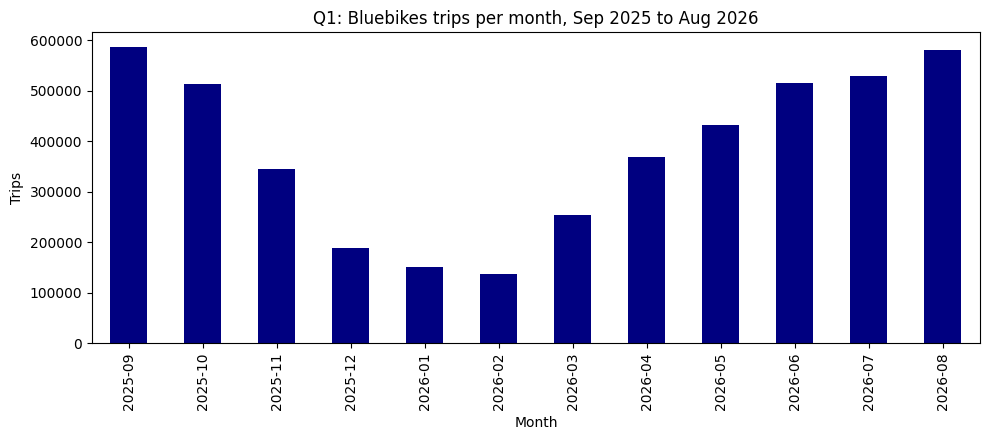

Busiest month: 2025-09 585895    quietest month: 2026-02 136103


In [21]:
monthly = trips.groupby("month").size()

monthly.plot(kind="bar", figsize=(10, 4.5), color="navy")
plt.title("Q1: Bluebikes trips per month, Sep 2025 to Aug 2026")
plt.xlabel("Month")
plt.ylabel("Trips")
plt.tight_layout()
plt.show()
print("Busiest month:", monthly.idxmax(), monthly.max(), "   quietest month:", monthly.idxmin(), monthly.min())

Demand is strongly seasonal. September 2025 was the busiest month with 585,895 trips, followed by August 2026 with 580,881, while February 2026 was the quietest with 136,103, about 4.3 times fewer. The rebalancing team needs much more capacity in late summer and early autumn than in winter.

**Q2: When during the day is the system busiest, and do weekends differ?**

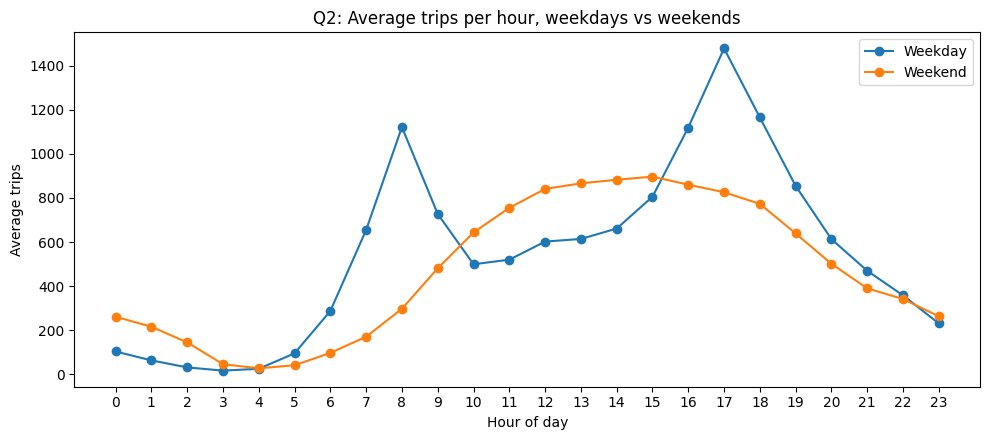

Weekday 8 am: 1121  5 pm: 1477  trips per hour
Weekend 8 am: 297  peak at 15 :00 with 896


In [22]:
weekday_trips = trips[trips["is_weekend"] == False]
weekend_trips = trips[trips["is_weekend"] == True]
weekday_avg = weekday_trips.groupby("hour").size() / weekday_trips["date"].nunique()
weekend_avg = weekend_trips.groupby("hour").size() / weekend_trips["date"].nunique()

plt.figure(figsize=(10, 4.5))
plt.plot(weekday_avg, marker="o", label="Weekday")
plt.plot(weekend_avg, marker="o", label="Weekend")
plt.title("Q2: Average trips per hour, weekdays vs weekends")
plt.xlabel("Hour of day")
plt.ylabel("Average trips")
plt.xticks(range(0, 24))
plt.legend()
plt.tight_layout()
plt.show()

print("Weekday 8 am:", round(weekday_avg[8]), " 5 pm:", round(weekday_avg[17]), " trips per hour")
print("Weekend 8 am:", round(weekend_avg[8]), " peak at", weekend_avg.idxmax(), ":00 with", round(weekend_avg.max()))

Weekdays have two commute peaks: about 1,121 trips in the 8 am hour and 1,477 in the 5 pm hour, the busiest hour of the week. Weekends have almost no morning rush (297 trips at 8 am) and build slowly to a single peak of 896 trips at 3 pm. The rebalancing team needs to be ready for the weekday evening peak, while the weekend plan can be lighter and later in the day.

#### Q3 (Grace)

**Q3: How is daily ridership associated with maximum temperature and precipitation?**

Each point is one calendar day. Wet days have PRCP greater than 0.

In [23]:
q3 = daily_weather.dropna(subset=["daily_trips", "TMAX", "PRCP"]).copy()
q3["conditions"] = np.where(q3["PRCP"] > 0, "Wet", "Dry")

print("Days used:", len(q3))
print(q3.groupby("conditions")["daily_trips"].agg(["size", "mean", "median"]).round(0))
r_temp = q3["TMAX"].corr(q3["daily_trips"])
print("Correlation between the daily high and daily trips:", round(r_temp, 3))

Days used: 365
            size     mean   median
conditions                        
Dry          238  14050.0  15416.0
Wet          127   9850.0   9947.0
Correlation between the daily high and daily trips: 0.825


           mean_trips  days
temp_band                  
10.0           2753.0     3
20.0           3330.0    16
30.0           5237.0    53
40.0           8525.0    47
50.0          11487.0    65
60.0          15018.0    46
70.0          17569.0    62
80.0          18729.0    57
90.0          16876.0    14
100.0         12212.0     2


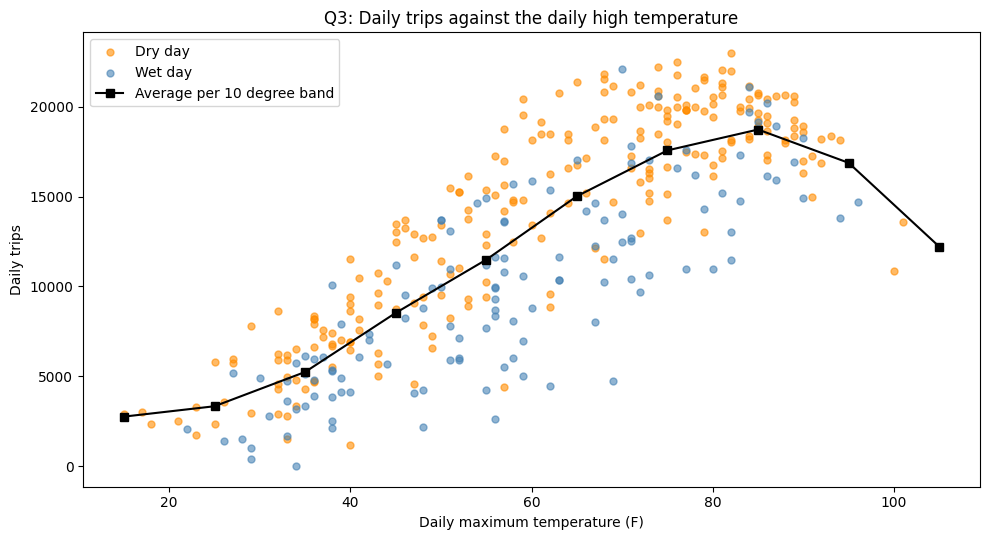

In [24]:
# 10 degree bands of the daily high (70 = 70 to 79 F), to see the shape of the relationship
q3["temp_band"] = (q3["TMAX"] // 10) * 10
band_means = q3.groupby("temp_band")["daily_trips"].agg(["mean", "size"]).round(0)
band_means.columns = ["mean_trips", "days"]
print(band_means)

q3_dry = q3[q3["conditions"] == "Dry"]
q3_wet = q3[q3["conditions"] == "Wet"]
plt.figure(figsize=(10, 5.5))
plt.scatter(q3_dry["TMAX"], q3_dry["daily_trips"], s=25, alpha=0.6, color="darkorange", label="Dry day")
plt.scatter(q3_wet["TMAX"], q3_wet["daily_trips"], s=25, alpha=0.6, color="steelblue", label="Wet day")
plt.plot(band_means.index + 5, band_means["mean_trips"], color="black", marker="s", label="Average per 10 degree band")
plt.title("Q3: Daily trips against the daily high temperature")
plt.xlabel("Daily maximum temperature (F)")
plt.ylabel("Daily trips")
plt.legend()
plt.tight_layout()
plt.show()

In [25]:
# Three drivers compared: rain, weekends and season
q3["is_weekend"] = q3["date"].dt.dayofweek >= 5
q3["month_num"] = q3["date"].dt.month
wet_mean = q3[q3["conditions"] == "Wet"]["daily_trips"].mean()
dry_mean = q3[q3["conditions"] == "Dry"]["daily_trips"].mean()
weekend_mean = q3[q3["is_weekend"] == True]["daily_trips"].mean()
weekday_mean = q3[q3["is_weekend"] == False]["daily_trips"].mean()
winter_mean = q3[q3["month_num"].isin([12, 1, 2])]["daily_trips"].mean()
summer_mean = q3[q3["month_num"].isin([6, 7, 8])]["daily_trips"].mean()

drivers = pd.DataFrame({"comparison": ["Wet vs dry", "Weekend vs weekday", "Winter vs summer"],
                        "group_a_mean": [wet_mean, weekend_mean, winter_mean],
                        "group_b_mean": [dry_mean, weekday_mean, summer_mean]})
drivers["pct_difference"] = (drivers["group_a_mean"] / drivers["group_b_mean"] - 1) * 100
drivers.round(1)

,comparison,group_a_mean,group_b_mean,pct_difference
0,Wet vs dry,9850.2,14049.6,-29.9
1,Weekend vs weekday,11262.6,13116.7,-14.1
2,Winter vs summer,5277.0,17661.0,-70.1


**Takeaway:** Daily trips are strongly related to temperature (r = 0.83), but not in a straight line. Average daily trips rise from about 2,750 on days in the 10s F to a peak of 18,729 in the 80s, then fall to 16,876 in the 90s and 12,212 on the two days above 100 F, so very hot days reduce ridership. Season has by far the largest effect: winter days have 70% fewer trips than summer days. Rain comes second, with 30% fewer trips on wet days (9,850 vs 14,050), and weekends third with 14% fewer trips than weekdays. These comparisons are unadjusted, the weather is measured at the airport, and a day counts as wet even if it rained for an hour. Rebalancing capacity should be planned mainly around the season, with smaller adjustments for rainy and very hot days.

#### Q4 (Eldo)

**Q4: Which stations lose or gain bikes through the day?** Net flow = arrivals minus departures per station per hour, on weekdays, averaged per weekday.

In [26]:
# Keep trips where both stations are in the station list, and add the hour at each end
t = trips[trips["stations_in_list"] == True].copy()
t["start_hour"] = t["started_at"].dt.hour
t["end_hour"] = t["ended_at"].dt.hour
print("Trips used:", len(t), "  dropped at unmatched stations:", len(trips) - len(t))

Trips used: 4535354   dropped at unmatched stations: 59424


In [27]:
# Weekday departures and arrivals per station and hour, and the net flow per weekday
t_dep = t[t["started_at"].dt.dayofweek < 5]
t_arr = t[t["ended_at"].dt.dayofweek < 5]
num_days = t_dep["started_at"].dt.date.nunique()

departures = t_dep.groupby(["start_key", "start_hour"]).size().reset_index()
departures.columns = ["name_key", "hour", "departures"]
arrivals = t_arr.groupby(["end_key", "end_hour"]).size().reset_index()
arrivals.columns = ["name_key", "hour", "arrivals"]

flow = departures.merge(arrivals, on=["name_key", "hour"], how="outer").fillna(0)
flow["net"] = flow["arrivals"] - flow["departures"]
flow["net_per_day"] = flow["net"] / num_days
flow = flow.merge(station_lookup[["station_name", "capacity"]], left_on="name_key", right_index=True, how="left")

print("Weekdays:", num_days, "  station-hours:", len(flow), "  rows without capacity:", flow["capacity"].isna().sum())
flow.head(3)

Weekdays: 261   station-hours: 14511   rows without capacity: 0


,name_key,hour,departures,arrivals,net,net_per_day,station_name,capacity
0,101 smith place,0,0.0,4.0,4.0,0.015326,101 Smith Place,23
1,101 smith place,1,4.0,1.0,-3.0,-0.011494,101 Smith Place,23
2,101 smith place,2,0.0,2.0,2.0,0.007663,101 Smith Place,23


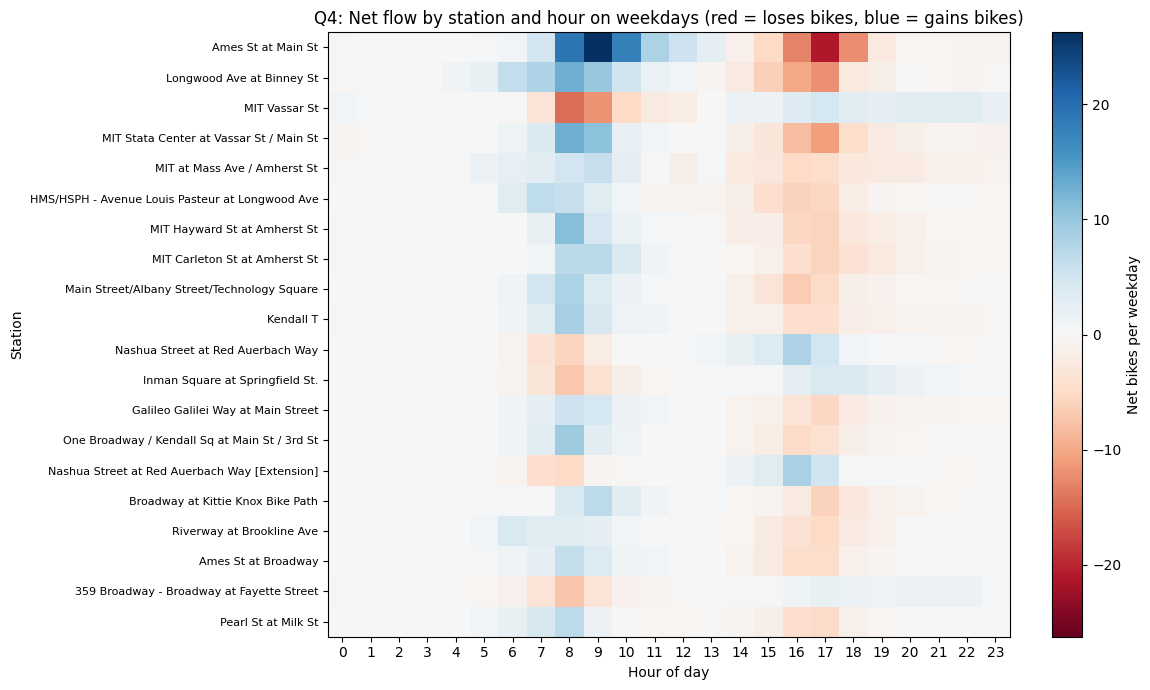

,station_name,hour,departures,arrivals,net_per_day,capacity,pct_of_capacity
1002,Ames St at Main St,17,6808.0,1350.0,-20.9,19,-110.1
9279,MIT Vassar St,8,4614.0,810.0,-14.6,53,-27.5
1001,Ames St at Main St,16,4631.0,1228.0,-13.0,19,-68.6
1003,Ames St at Main St,18,4212.0,1006.0,-12.3,19,-64.7
8237,Longwood Ave at Binney St,17,3694.0,560.0,-12.0,15,-80.1
9280,MIT Vassar St,9,3745.0,689.0,-11.7,53,-22.1
9264,MIT Stata Center at Vassar St / Main St,17,4440.0,1598.0,-10.9,35,-31.1
8236,Longwood Ave at Binney St,16,3157.0,516.0,-10.1,15,-67.5
9263,MIT Stata Center at Vassar St / Main St,16,3659.0,1554.0,-8.1,35,-23.0
262,359 Broadway - Broadway at Fayette Street,8,2631.0,758.0,-7.2,23,-31.2


In [28]:
# The 20 stations with the biggest total daily imbalance, as a station x hour heatmap
flow["abs_net"] = flow["net_per_day"].abs()
top20 = flow.groupby("name_key")["abs_net"].sum().nlargest(20).index
pivot = flow[flow["name_key"].isin(top20)].pivot_table(index="station_name", columns="hour", values="net_per_day")
pivot = pivot.reindex(columns=range(24)).fillna(0)
station_order = pivot.abs().sum(axis=1).sort_values(ascending=False).index
pivot = pivot.loc[station_order]

plt.figure(figsize=(12, 7))
maxval = pivot.abs().values.max()
plt.imshow(pivot.values, cmap="RdBu", vmin=-maxval, vmax=maxval, aspect="auto")
plt.xticks(range(24), range(24))
plt.yticks(range(len(pivot)), pivot.index, fontsize=8)
plt.xlabel("Hour of day")
plt.ylabel("Station")
plt.title("Q4: Net flow by station and hour on weekdays (red = loses bikes, blue = gains bikes)")
plt.colorbar(label="Net bikes per weekday")
plt.tight_layout()
plt.show()

# The 10 worst station-hours
drain10 = flow.sort_values("net_per_day").head(10)[["station_name", "hour", "departures", "arrivals", "net_per_day", "capacity"]]
drain10["pct_of_capacity"] = drain10["net_per_day"] / drain10["capacity"] * 100
drain10.round(1)

A few stations near MIT and the Longwood medical area account for most of the imbalance, and it happens in the commute hours. Ames St at Main St loses about 20.9 bikes on an average weekday in the 5 pm hour alone (6,808 departures against 1,350 arrivals over the year), more than its 19 docks. MIT Vassar St loses 14.6 bikes in the 8 am hour. The worst cases are the same few stations in the morning rush (8 to 9 am) or the evening rush (4 to 6 pm), so the problem is people travelling in one direction at a time. One caveat: the vans already move bikes during the day, so these numbers show how strong the imbalance is, not that a station actually ran dry. A value of -110% of capacity means the vans had to keep refilling it.

## 3. Is the shortage pattern predictable from trip history? (Daniel)

If the same stations drain at the same hours all year, Bluebikes can plan for it from data it already has. Three checks, one chart each (charts 5 to 7).

| # | Question | Chart |
|---|---|---|
| Q5 | Do the same stations top the drainer and filler lists in both halves of the year? | scatter: Sep to Feb vs Mar to Aug |
| Q6 | Does the rush-hour drain happen every week, or only sometimes? | weekly lines, top 5 drainers |
| Q7 | Does rain change which stations drain, or only how many ride? | scatter: dry vs wet |

First we need a station x date x hour version of the Q4 flow table, so that we can split the year into periods.

In [29]:
# One row per station, date and hour, built from the matched trips
t2 = t.copy()
t2["start_date"] = t2["started_at"].dt.normalize()
t2["end_date"] = t2["ended_at"].dt.normalize()
dep = t2.groupby(["start_key", "start_date", "start_hour"]).size().reset_index()
dep.columns = ["name_key", "date", "hour", "departures"]
arr = t2.groupby(["end_key", "end_date", "end_hour"]).size().reset_index()
arr.columns = ["name_key", "date", "hour", "arrivals"]
sh = dep.merge(arr, on=["name_key", "date", "hour"], how="outer").fillna(0)
sh["net"] = sh["arrivals"] - sh["departures"]
sh["is_weekend"] = sh["date"].dt.dayofweek >= 5
sh["half"] = np.where(sh["date"] < "2026-03-01", "H1", "H2")

# Net bikes per day for a set of hours: sum the net flow over those hours and divide by the number of days
def net_per_day(df, hours):
    n_days = df["date"].nunique()
    return df[df["hour"].isin(hours)].groupby("name_key")["net"].sum() / n_days

wkday = sh[sh["is_weekend"] == False]
AM = [7, 8, 9]
am_drain = net_per_day(wkday, AM)
print("Rows in sh:", len(sh))
print(am_drain.nsmallest(5).rename(index=station_lookup["station_name"]).round(1))

Rows in sh: 2240912
name_key
MIT Vassar St                                        -30.0
359 Broadway - Broadway at Fayette Street            -14.4
Inman Square at Springfield St.                      -14.2
Cambridge Dept. of Public Works -147 Hampshire St.   -12.0
MIT Pacific St at Purrington St                      -11.7
Name: net, dtype: float64


### Q5: Do the same stations top the list in both halves of the year?

Stations compared: 458
Drainers in both halves: 18 of 20   fillers in both halves: 18 of 20
Correlation r: 0.972


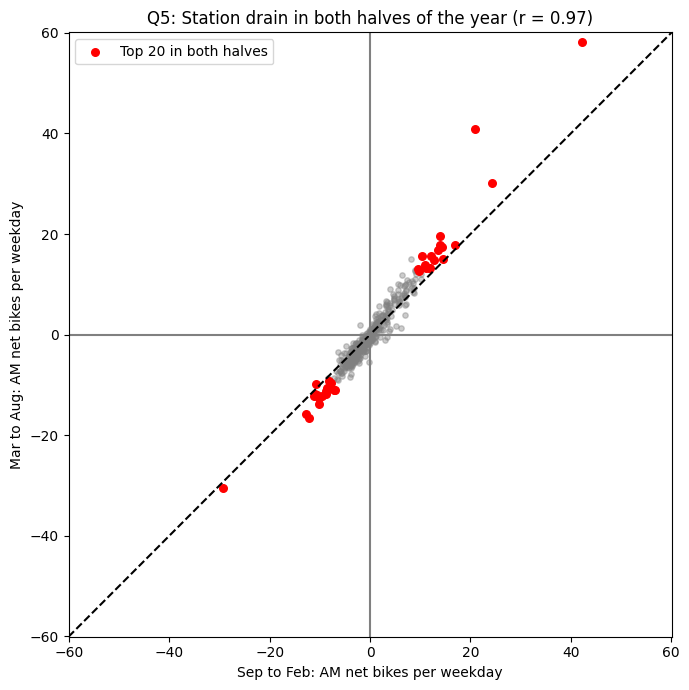

In [30]:
# Morning (7 to 9 am) net flow per station in each half of the year
h1 = net_per_day(wkday[wkday["half"] == "H1"], AM)
h2 = net_per_day(wkday[wkday["half"] == "H2"], AM)
q5 = pd.DataFrame({"H1": h1, "H2": h2}).dropna()
q5 = q5[(q5["H1"].abs() > 0.5) | (q5["H2"].abs() > 0.5)]   # stations that gain or lose more than half a bike

drain_h1 = q5["H1"].nsmallest(20).index
drain_h2 = q5["H2"].nsmallest(20).index
fill_h1 = q5["H1"].nlargest(20).index
fill_h2 = q5["H2"].nlargest(20).index
r_halves = q5["H1"].corr(q5["H2"])
print("Stations compared:", len(q5))
print("Drainers in both halves:", drain_h1.isin(drain_h2).sum(), "of 20   fillers in both halves:", fill_h1.isin(fill_h2).sum(), "of 20")
print("Correlation r:", round(r_halves, 3))

both = drain_h1[drain_h1.isin(drain_h2)].union(fill_h1[fill_h1.isin(fill_h2)])
plt.figure(figsize=(7, 7))
plt.scatter(q5["H1"], q5["H2"], color="grey", alpha=0.4, s=15)
plt.scatter(q5.loc[both, "H1"], q5.loc[both, "H2"], color="red", s=30, label="Top 20 in both halves")
lim = q5.abs().max().max() + 2
plt.plot([-lim, lim], [-lim, lim], "--", color="black")
plt.axhline(0, color="grey")
plt.axvline(0, color="grey")
plt.xlim(-lim, lim)
plt.ylim(-lim, lim)
plt.xlabel("Sep to Feb: AM net bikes per weekday")
plt.ylabel("Mar to Aug: AM net bikes per weekday")
plt.title(f"Q5: Station drain in both halves of the year (r = {r_halves:.2f})")
plt.legend()
plt.tight_layout()
plt.show()

**Answer:** Yes. 18 of the top 20 drainers and 18 of the top 20 fillers are the same in both halves of the year (r = 0.97). MIT Vassar St, for example, loses about 29 to 31 bikes every weekday morning in both halves. The problem stations are predictable, so Bluebikes can plan morning rebalancing ahead of time from past trip data.

### Q6: Does the rush-hour drain happen every week, or only sometimes?

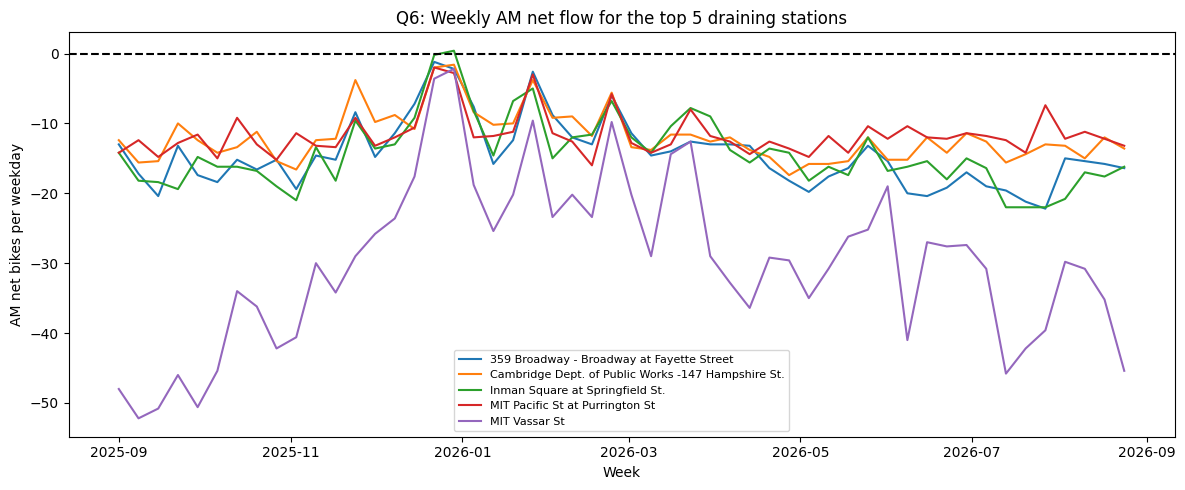

Weeks: 52
name_key
359 Broadway - Broadway at Fayette Street             100.0
Cambridge Dept. of Public Works -147 Hampshire St.    100.0
Inman Square at Springfield St.                        98.1
MIT Pacific St at Purrington St                       100.0
MIT Vassar St                                         100.0
dtype: float64


In [31]:
# Weekly morning net flow for the five biggest drainers, divided by the number of weekdays in each week
top5 = am_drain.nsmallest(5).index
q6 = wkday[(wkday["name_key"].isin(top5)) & (wkday["hour"].isin(AM))].copy()
q6["week"] = q6["date"].dt.to_period("W").dt.start_time
weekly_net = q6.groupby(["name_key", "week"])["net"].sum()

days = wkday[["date"]].drop_duplicates()
days["week"] = days["date"].dt.to_period("W").dt.start_time
days_per_week = days.groupby("week")["date"].count()

weekly = weekly_net.unstack("name_key")
weekly = weekly.div(days_per_week, axis=0)
weekly = weekly[days_per_week >= 3]   # drop weeks with fewer than 3 weekdays
weekly = weekly.rename(columns=station_lookup["station_name"])

plt.figure(figsize=(12, 5))
for station in weekly.columns:
    plt.plot(weekly.index, weekly[station], label=station)
plt.axhline(0, color="black", linestyle="--")
plt.title("Q6: Weekly AM net flow for the top 5 draining stations")
plt.xlabel("Week")
plt.ylabel("AM net bikes per weekday")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

neg_share = (weekly < 0).mean() * 100   # % of weeks in which the station lost bikes
print("Weeks:", len(weekly))
print(neg_share.round(1))

**Answer:** The drain happens almost every week: 4 of the top 5 stations lost bikes in 100% of weeks and Inman Square in 98%, with only the Christmas break close to zero. MIT Vassar St follows the school calendar, from about 50 bikes lost per morning in September to near zero in late December. These stations can go on a fixed morning schedule, adjusted for the school calendar.

### Q7: Does rain change which stations drain, or only how many ride?

Wet weekdays: 85   dry weekdays: 176
Stations compared: 434   Spearman rho: 0.995   top-20 overlap: 19 of 20   slope: 0.8


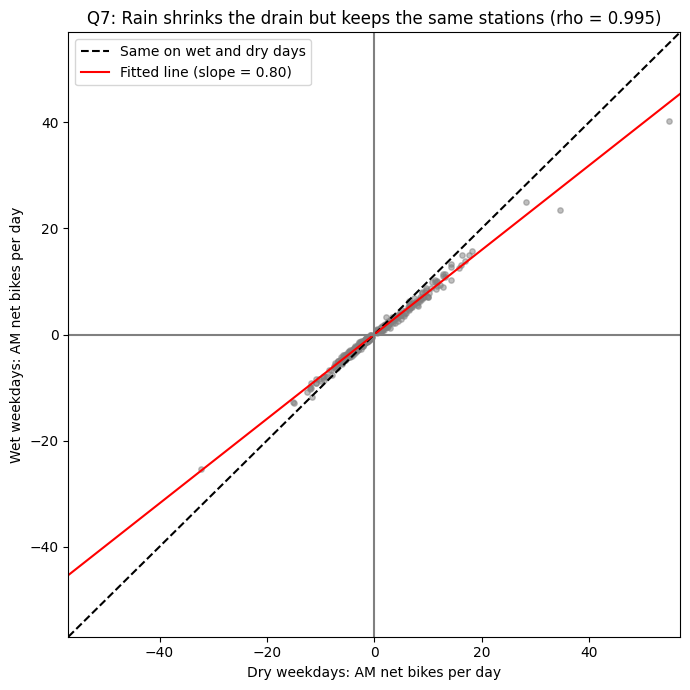

In [32]:
# Morning net flow per station on wet weekdays (any rain or snow at Logan) and on dry weekdays
wet_days = weather.loc[weather["PRCP"] > 0, "DATE"]
wk_wet = wkday[wkday["date"].isin(wet_days)]
wk_dry = wkday[~wkday["date"].isin(wet_days)]
print("Wet weekdays:", wk_wet["date"].nunique(), "  dry weekdays:", wk_dry["date"].nunique())

q7 = pd.DataFrame({"dry": net_per_day(wk_dry, AM), "wet": net_per_day(wk_wet, AM)}).dropna()
q7 = q7[(q7["dry"].abs() > 0.5) | (q7["wet"].abs() > 0.5)]
rho_rain = q7["dry"].corr(q7["wet"], method="spearman")   # same order of stations on wet and dry days?
slope, intercept = np.polyfit(q7["dry"], q7["wet"], 1)    # how much smaller the drain is on wet days
dry20 = q7["dry"].nsmallest(20).index
wet20 = q7["wet"].nsmallest(20).index
print("Stations compared:", len(q7), "  Spearman rho:", round(rho_rain, 3), "  top-20 overlap:", dry20.isin(wet20).sum(), "of 20   slope:", round(slope, 2))

plt.figure(figsize=(7, 7))
plt.scatter(q7["dry"], q7["wet"], color="grey", alpha=0.5, s=15)
lim = q7.abs().max().max() + 2
plt.plot([-lim, lim], [-lim, lim], "--", color="black", label="Same on wet and dry days")
plt.plot([-lim, lim], [slope * -lim + intercept, slope * lim + intercept], color="red", label=f"Fitted line (slope = {slope:.2f})")
plt.axhline(0, color="grey")
plt.axvline(0, color="grey")
plt.xlim(-lim, lim)
plt.ylim(-lim, lim)
plt.xlabel("Dry weekdays: AM net bikes per day")
plt.ylabel("Wet weekdays: AM net bikes per day")
plt.title(f"Q7: Rain shrinks the drain but keeps the same stations (rho = {rho_rain:.3f})")
plt.legend()
plt.tight_layout()
plt.show()

**Answer:** Rain or snow changes how many people ride, not where the drain happens. The station ranking is almost the same on wet and dry days (Spearman rho = 0.995) and 19 of the top 20 drainers overlap. On wet days the morning drain is about 80% of a dry day (slope = 0.80). On wet days Bluebikes can keep the same routes and move about 20% fewer bikes.

Takeaway: The morning drain is a stable, predictable pattern. The same stations top the list in both halves of the year (Q5), they lose bikes almost every week (Q6), and rain only makes the drain smaller without moving it (Q7). Trip history alone is enough to tell Bluebikes where morning pressure will be, though Section 5 shows it cannot say which of these stations actually run empty.



## 4. What does the live feed show? (Adham)

The log was thin until Oct 7 (GitHub ran the logger about 6 times a day). From Oct 7 it is 10-minute data, so this section uses the **dense period only**. Four charts (8 to 11).

| # | Question | Chart |
|---|---|---|
| Q8 | How often are stations empty or full, and at what hours? | lines by hour, weekday vs weekend |
| Q9 | Which stations are empty most, and at what hours? | heatmap |
| Q10 | How much rebalancing is Bluebikes already doing? | bars: van visits by hour |
| Q11 | Which stations are empty or full most often, and how concentrated is the problem? | bars: 10 most often empty, 10 most often full |

In [33]:

gbfs["name_key"] = norm_name(gbfs["name"])
gbfs["day_name"] = gbfs["snapshot"].dt.day_name()

## find the first day with at least 36 snapshots as this is when we editted the logger
snaps_per_day = gbfs.groupby("date")["snapshot"].nunique()
DENSE_FROM = snaps_per_day[snaps_per_day >= 36].index.min()


dense = gbfs[gbfs["date"] >= DENSE_FROM] # Keep the period with more frequent readings
wd_dense = dense[dense["is_weekend"] == False]
we_dense = dense[dense["is_weekend"] == True]

# Check that weekdays and weekends have readings across all hours
hour_cover = dense.drop_duplicates("snapshot")
hour_cover = hour_cover.groupby(["is_weekend", "hour"]).size().unstack(0) ## put weekday and weekend counts in separate columns



print("Dense period starts:", DENSE_FROM)
print("Dense days:", dense["date"].nunique())
print("Total snapshots:", dense["snapshot"].nunique())
print("Minimum weekday snapshots per hour:", hour_cover[False].min())
print("Minimum weekend snapshots per hour:", hour_cover[True].min())


Dense period starts: 2026-10-07
Dense days: 11
Total snapshots: 1384
Minimum weekday snapshots per hour: 31
Minimum weekend snapshots per hour: 12


### Q8: How often are stations empty or full, and at what hours?

Our Team Assignment version of this chart used the whole log, including the sparse September days. This one uses the dense period only and splits weekdays from weekends.

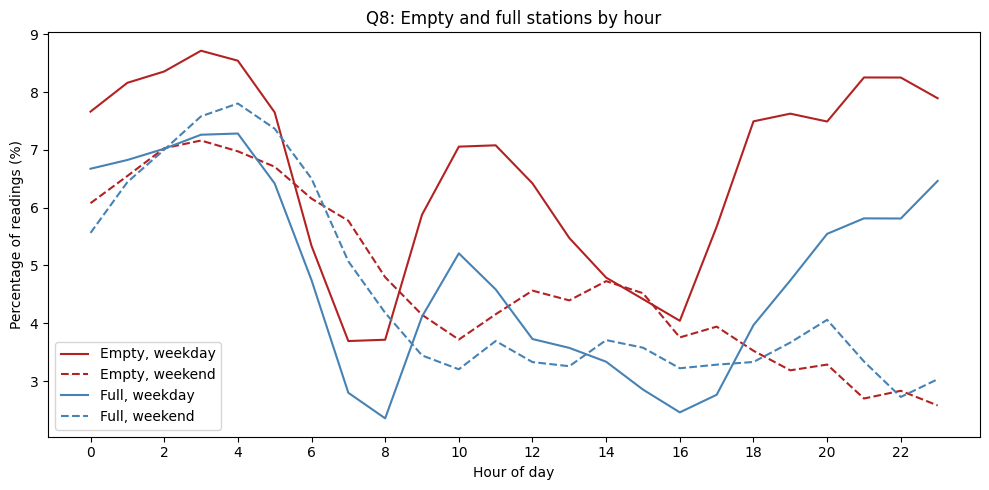

In [34]:
wd = wd_dense.groupby("hour")[["is_empty", "is_full"]].mean() * 100 #calculate the percent of empty and full readings for each hour
we = we_dense.groupby("hour")[["is_empty", "is_full"]].mean() * 100





plt.figure(figsize=(10, 5))

# Solid lines for weekdays, dashed lines for weekends
plt.plot(wd.index, wd["is_empty"], color="firebrick", label="Empty, weekday")
plt.plot(we.index, we["is_empty"], "--", color="firebrick", label="Empty, weekend")
plt.plot(wd.index, wd["is_full"], color="steelblue", label="Full, weekday")
plt.plot(we.index, we["is_full"], "--", color="steelblue", label="Full, weekend")

plt.title("Q8: Empty and full stations by hour")
plt.xlabel("Hour of day")
plt.ylabel("Percentage of readings (%)")
plt.xticks(range(0, 24, 2))
plt.legend()
plt.tight_layout()
plt.show()


In [35]:

## comparing empty rates during the morning and evening
morning = wd.loc[7:9, "is_empty"].mean()
evening = wd.loc[16:18, "is_empty"].mean()


# w eekday vs weekend empty rates
weekday_empty = wd_dense["is_empty"].mean() * 100
weekend_empty = we_dense["is_empty"].mean() * 100

print(f"Morning empty rate: {round(morning, 1)} %")
print(f"Evening empty rate: {round(evening, 1)} %")
print(f"Weekday empty rate: {round(weekday_empty, 1)} %")
print(f"Weekend empty rate: {round(weekend_empty, 1)} %")


Morning empty rate: 4.4 %
Evening empty rate: 5.7 %
Weekday empty rate: 6.7 %
Weekend empty rate: 4.8 %


**Answer:** Stations are more likely to be empty overnight than during the morning commute. On weekdays, the empty rate is lowest at 7 am (3.7%), rises to around 7.5 to 8.3% after 6 pm, and peaks at 3 am (8.7%). Full stations follow a similar pattern, peaking at 4 am (7.3%).

The morning empty rate (7 to 9 am) averages 4.4%, compared with 5.7% in the evening (4 to 6 pm). Hours with more departures tend to have fewer empty and full stations, with correlations of -0.63 and -0.87, so trip demand alone does not explain shortages. Empty rates are also higher on weekdays (6.7%) than weekends (4.8%).

One limitation is that our dense log covers only one or two dates for each day of the week. The only Monday recorded was the October 12 holiday, so it may not represent a typical Monday.

**Takeaway:** Shortages build up in the evening and persist overnight. Evening rebalancing is worth exploring, although we would need information about current van schedules to confirm whether additional evening runs would help.

### Q9: Which stations are empty most, and at what hours?

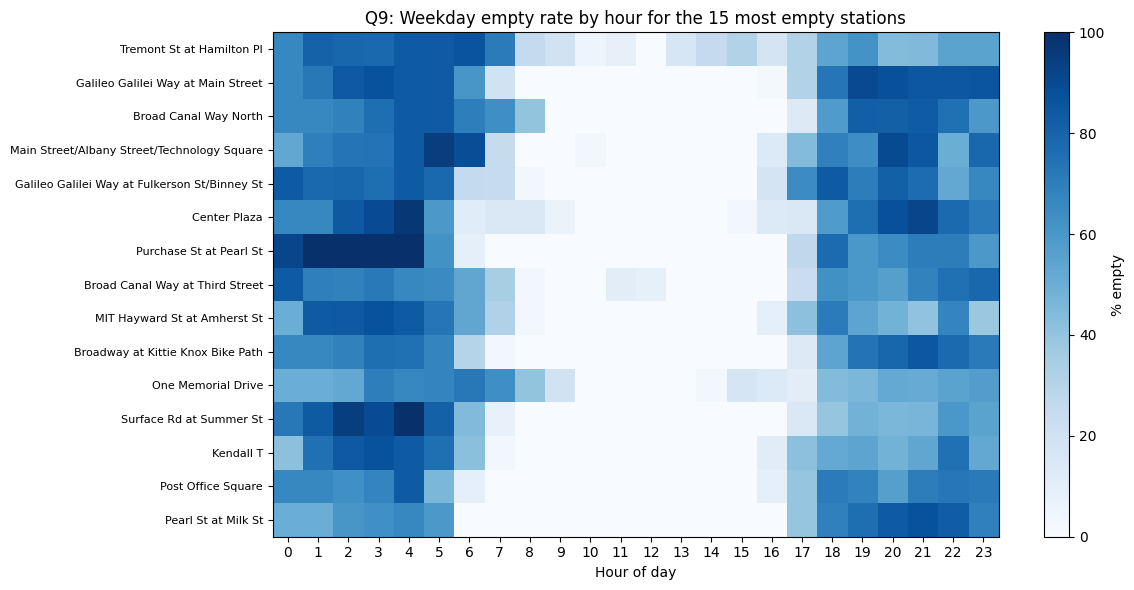

Most often empty: Tremont St at Hamilton Pl 46.8 %


In [36]:
empty = wd_dense.groupby(["name_key", "hour"])["is_empty"].mean() * 100 #calculating empty rates by hour for a station on a weekday using dense dataset

empty = empty.unstack() #Convert hours to columns for heatmaps

#15 stations with the highest average empty rate
top15 = empty.mean(axis=1).nlargest(15).index
#keep only stations and have hours run from 0 to 23 to make sure heatmap displays all 24 hours in order
top = empty.loc[top15].reindex(columns=range(24))
## replace the short station key with the real station name
top.index = top.index.map(station_lookup["station_name"])

### Plotting
plt.figure(figsize=(12, 6))
plt.imshow(top, cmap="Blues", aspect="auto", vmin=0, vmax=100)
plt.xticks(range(24))
plt.yticks(range(len(top.index)), top.index, fontsize=8)
plt.xlabel("Hour of day")
plt.title("Q9: Weekday empty rate by hour for the 15 most empty stations")
plt.colorbar(label="% empty")
plt.tight_layout()
plt.show()

## showing the station with the highests avg empty rate
worst_station = top.index[0]
worst_rate = top.iloc[0].mean()

print("Most often empty:", worst_station, round(worst_rate, 1), "%")

**Answer:** The stations that are empty most on weekdays are not the Q4 morning drainers. The top 15 are office and campus stations in Kendall Square and downtown (Tremont St at Hamilton Pl is empty in 46.8% of weekday readings, then Galileo Galilei Way at Main Street, Broad Canal Way North, Technology Square, Center Plaza and Purchase St at Pearl St), and none of them is in the Section 3 top 20 morning drainer list. The heatmap shows why: they are empty from about 6 pm right through to 6 or 7 am (72 to 83% empty between 1 and 5 am), are refilled before 8 am, and stay stocked all day. The evening commute rides the bikes away and nobody brings them back until the vans do.

**Takeaway:** These 15 stations need bikes delivered in the evening or overnight, which is the opposite timing from the morning drainers.

### Q10: How much rebalancing is Bluebikes already doing?

A van visit shows up as a jump in bikes between two snapshots that riders could not produce. We compare each reading with the previous reading of the same station and count jumps of at least 5 bikes (or 30% of capacity, whichever is larger) within 20 minutes.

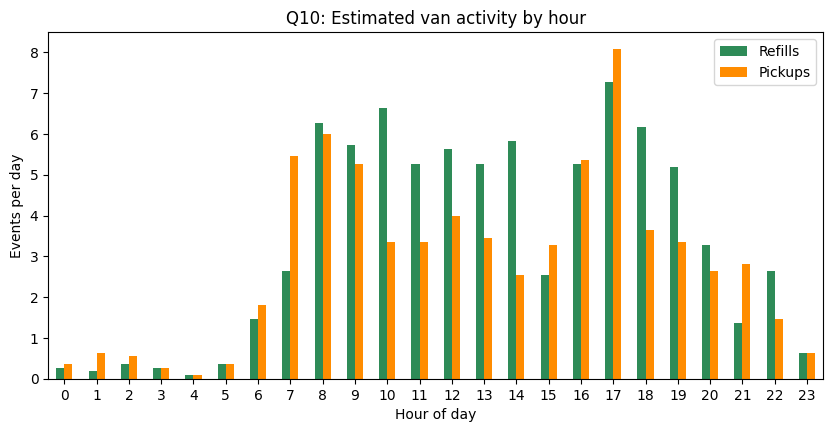

Average refills per day: 80.6
Average pickups per day: 68.8


In [37]:

# Sort each station's readings from earliest to latest
d = dense.sort_values(["station_id", "snapshot"]).copy()


d["change"] = d.groupby("station_id")["num_bikes_available"].diff() ##finding num of bikes added or removed since last reading
d["minutes"] = d.groupby("station_id")["snapshot"].diff().dt.total_seconds() / 60 #sec -> min

# require a change of at least 5 bikes or 30% of the station's capacity
d["limit"] = d["capacity"] * 0.3 ## I chose 30% of capacity randomly, the idea is that I dont want to mark every change as a van visit
d["limit"] = d["limit"].clip(lower=5)


# setting large increases or decreases as possible van refills or pickups
# Both must happen within 20 minutes
d["refill"] = (d["change"] >= d["limit"]) & (d["minutes"] <= 20)
d["pickup"] = (d["change"] <= -d["limit"]) & (d["minutes"] <= 20)

# Count the number of different days in the dense period
dense_days = d["date"].nunique()

# Count possible refills and pickups for each hour
# sum() counts True as 1 and False as 0
hourly = d.groupby("hour")[["refill", "pickup"]].sum()

# Divide by the number of days to get the daily average
hourly = hourly / dense_days

# Plot the average by hour
hourly.plot(kind="bar", figsize=(10, 4.5), color=["seagreen", "darkorange"])
plt.title("Q10: Estimated van activity by hour")
plt.xlabel("Hour of day")
plt.ylabel("Events per day")
plt.xticks(rotation=0)
plt.legend(["Refills", "Pickups"])
plt.show()

# Showing the daily average number of estimated visits
print("Average refills per day:", round(d["refill"].sum() / dense_days, 1))
print("Average pickups per day:", round(d["pickup"].sum() / dense_days, 1))


**Answer:** The log suggests that Bluebikes already moves a lot of bikes through the day. We counted around 80 possible refills and 69 pickups per day, based on changes of at least 5 bikes or 30% of station capacity within 20 minutes.

Refills were most common at 5 pm, 10 am and 8 am. The most frequently refilled stations were Longwood Ave at Binney St (2.2 times per day), Watermark Seaport, Commonwealth Ave at Agganis Way, Harvard Square and Ames St at Main St. None of these stations is among the top 20 morning drainers in Section 3, so the vans seem to be chasing the evening drainers and the big destination stations rather than the morning drainers.

These are estimates. A large change could also come from several riders arriving or leaving within a short period rather than a van visit, so the counts are an upper bound.

**Takeaway:** Bikes are redistributed throughout the day, but some stations still sit empty overnight (Q9). Reviewing evening rebalancing could be worthwhile, although actual van records would be needed to confirm where the gaps are.

### Q11: Which stations are empty or full most often, and how concentrated is the problem?

Share of dense readings empty and full per station, for stations with at least 300 readings. The chart shows the ten worst of each kind.

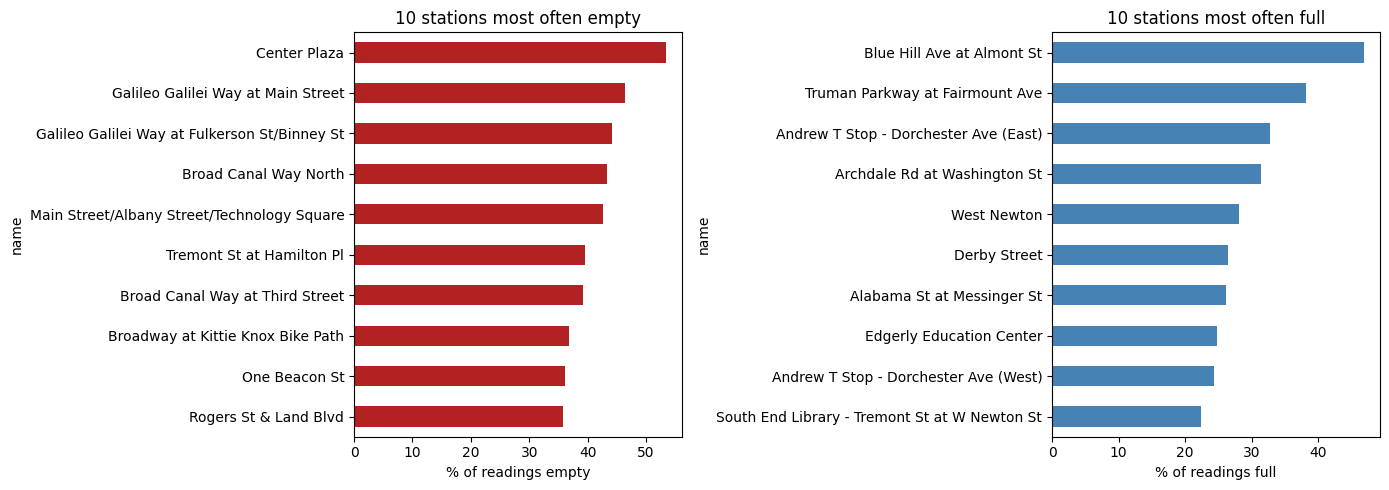

Stations in both top-10 lists: 0


In [38]:

# Calculate all percentages for each station
station_rates = dense.groupby("name")[["is_empty", "is_full"]].mean() * 100
station_rates["readings"] = dense.groupby("name").size() #count per station regardless of nan readings as I want to know how many readings were collected

station_rates = station_rates[station_rates["readings"] >= 300] ## keep densly recorded station (300 is random)

# Find the 10 stations empty and full
top10_empty = station_rates.sort_values("is_empty", ascending=False).head(10)
top10_full = station_rates.sort_values("is_full", ascending=False).head(10)

# plot and set axes for side by side horizontal bar
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
top10_empty["is_empty"].sort_values().plot(kind="barh", ax=axes[0], color="firebrick")
axes[0].set_title("10 stations most often empty")
axes[0].set_xlabel("% of readings empty")

top10_full["is_full"].sort_values().plot(kind="barh", ax=axes[1], color="steelblue")
axes[1].set_title("10 stations most often full")
axes[1].set_xlabel("% of readings full")

plt.tight_layout() # for the two axes to remain separate
plt.show()

# Check if any stations appear in both top-10 lists
overlap = top10_empty.index.isin(top10_full.index).sum()
print("Stations in both top-10 lists:", overlap)


In [39]:

# median empty and full rates for every station
print("Median empty rate:", round(station_rates["is_empty"].median(), 1), "%")
print("Median full rate:", round(station_rates["is_full"].median(), 1), "%")

empty_counts = dense.groupby("name")["is_empty"].sum()
empty_counts = empty_counts.sort_values(ascending=False)

full_counts = dense.groupby("name")["is_full"].sum()
full_counts = full_counts.sort_values(ascending=False)

#calculating percentage of all shortages coming from the worst 20
empty_share = empty_counts.head(20).sum() / empty_counts.sum() * 100
print("Empty readings from top 20 stations:", round(empty_share, 1), "%")
full_share = full_counts.head(20).sum() / full_counts.sum() * 100
print("Full readings from top 20 stations:", round(full_share, 1), "%")


Median empty rate: 2.4 %
Median full rate: 2.7 %
Empty readings from top 20 stations: 19.5 %
Full readings from top 20 stations: 16.8 %


**Answer:** The stations most often empty and most often full are in different areas. Empty stations are concentrated around Kendall Square and downtown. Center Plaza has the highest empty rate (53.4%), followed by Galileo Galilei Way at Main Street (46.5%), Galileo Galilei Way at Fulkerson St (44.3%), Broad Canal Way North (43.4%) and Technology Square (42.7%).

Full stations are smaller stations in residential areas. The highest rates are at Blue Hill Ave at Almont St (47.1%), Truman Parkway at Fairmount Ave (38.2%), Andrew T Stop East (32.9%), Archdale Rd (31.4%) and West Newton (28.1%). No station appears on both top-10 lists.

Out of 624 stations, 173 were never recorded as empty and 181 were never full. The median empty rate is only 2.4% and the median full rate 2.8%. But the 20 stations with the most empty readings account for 19.5% of all empty readings, and the top 20 for full readings account for 16.8%.

**Takeaway:** Shortages are concentrated in a small number of stations. A delivery list of about 20 stations and a pickup list of about 20 stations would cover roughly a fifth of the observed shortages.

## 5. Which station-hours should Bluebikes prioritise?


This section answers success metrics M2, M3 and M5. Charts 12 to 15.

| # | Question | Output |
|---|---|---|
| Q12 | Does historical morning drain predict live morning empties? (hour-matched) | bar by drain quartile; k and rho |
| Q13 | Does the log predict itself? (train / test split) | scatter; station-hour table |
| Q14 | The priority list | bar: top 20 bike-shortage and top 20 dock-shortage station-hours; CSV; riders affected |
| Q15 | Pair each drainer with its nearest filler | map with arrows; table |

### Q12: Does historical pressure predict live stock-outs? (hour-matched) (Mia)

In the Team Assignment we compared the 20 biggest morning drainers with all weekday readings of the log and found almost no difference (empty 7.1% of the time against 6.7% for the rest). Here the hours are matched: the morning (7 to 9 am) empty rate per station from the dense weekday readings, next to the morning drain from a year of trips. Stations are split into four equal groups by their morning drain.

In [40]:
am_rows = wd_dense[wd_dense["hour"].isin(AM)]
am_live = am_rows.groupby("name_key")["is_empty"].mean() * 100
am_count = am_rows.groupby("name_key").size()

val12 = pd.DataFrame({"am_net_per_day": am_drain, "am_empty_rate": am_live, "readings": am_count}).dropna()
val12 = val12[val12["readings"] >= 20]
val12["group"] = pd.qcut(val12["am_net_per_day"], 4, labels=["1 Biggest drainers", "2 Moderate", "3 Small", "4 Gainers"])
emptypercent = val12.groupby("group", observed=True)["am_empty_rate"].mean()

overall = val12["am_empty_rate"].mean()
k = emptypercent["1 Biggest drainers"] / overall
rho_12 = val12["am_net_per_day"].corr(val12["am_empty_rate"], method="spearman")
print("Stations compared:", len(val12), "  fewest morning readings:", int(val12["readings"].min()), "  stations per group:", val12["group"].value_counts().min(), "to", val12["group"].value_counts().max())
print(emptypercent.round(1))
print("Overall morning empty rate:", round(overall, 1), "%")
print("k (biggest drainers / overall):", round(k, 2))
print("Spearman rho (drain vs empty rate):", round(rho_12, 2))

Stations compared: 607   fewest morning readings: 107   stations per group: 150 to 153
group
1 Biggest drainers    7.0
2 Moderate            3.3
3 Small               2.0
4 Gainers             5.3
Name: am_empty_rate, dtype: float64
Overall morning empty rate: 4.4 %
k (biggest drainers / overall): 1.59
Spearman rho (drain vs empty rate): -0.14


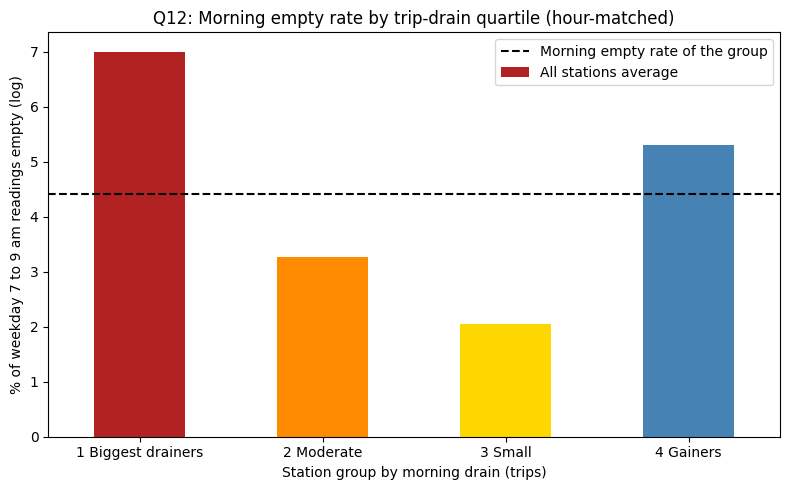

20 biggest drainers, mean morning empty rate: 12.9 %   all other stations: 4.1 %


,am_net_per_day,am_empty_rate,readings,group
name_key,,,,
MIT Vassar St,-30.0,3.7,107.0,1 Biggest drainers
359 Broadway - Broadway at Fayette Street,-14.4,13.1,107.0,1 Biggest drainers
Inman Square at Springfield St.,-14.2,21.5,107.0,1 Biggest drainers
Cambridge Dept. of Public Works -147 Hampshire St.,-12.0,27.1,107.0,1 Biggest drainers
MIT Pacific St at Purrington St,-11.7,11.2,107.0,1 Biggest drainers
Dana Park,-11.4,10.3,107.0,1 Biggest drainers
Nashua Street at Red Auerbach Way,-11.4,10.3,107.0,1 Biggest drainers
Kennedy-Longfellow School 158 Spring St,-11.3,17.8,107.0,1 Biggest drainers
W Broadway at D St,-10.9,23.4,107.0,1 Biggest drainers


In [41]:
emptypercent.plot(kind="bar", figsize=(8, 5), color=["firebrick", "darkorange", "gold", "steelblue"])
plt.axhline(overall, color="black", linestyle="--")
plt.xlabel("Station group by morning drain (trips)")
plt.ylabel("% of weekday 7 to 9 am readings empty (log)")
plt.title("Q12: Morning empty rate by trip-drain quartile (hour-matched)")
plt.xticks(rotation=0)
plt.legend(["Morning empty rate of the group", "All stations average"])
plt.tight_layout()
plt.show()

# the 20 biggest drainers one by one: do the vans keep them stocked?
top20_12 = val12.sort_values("am_net_per_day").head(20)
print("20 biggest drainers, mean morning empty rate:", round(top20_12["am_empty_rate"].mean(), 1), "%   all other stations:", round(val12.sort_values("am_net_per_day").iloc[20:]["am_empty_rate"].mean(), 1), "%")
top20_12.head(10).rename(index=station_lookup["station_name"]).round(1)

**Answer:** Morning trip patterns help predict which stations will be empty, but not reliably. The 152 stations that lose the most bikes in the morning were empty 7.0% of the time between 7 and 9 am, compared with the overall average of 4.4%. This is 1.59 times higher, so we met our target of 1.5.

However, the rank correlation was only -0.14, weaker than our target of -0.3. Some stations that lose a lot of bikes are rarely empty, while others that lose fewer bikes have much higher empty rates. MIT Vassar St loses around 30 bikes every morning but was empty only 3.7% of the time, while Cambridge Dept. of Public Works loses around 12 bikes and was empty 27.1% of the time. Stations that gain bikes in the morning still had a relatively high empty rate (5.3%), because they were already empty from the previous evening (Q9).

**Takeaway:** Historical trip data is useful for finding stations that might have problems, but it cannot rank them. We also need the live station data to see which stations actually run out of bikes.

### Q13: Does the log predict itself? (train / test split)(Mia)

A pattern is only useful if it holds in data we have not looked at. The last three full days of the log are the test period and everything before is the training period, so nothing from the test days is used to build the rankings.

Training: 2026-09-16 to 2026-10-14   readings: 703469
Test:     [datetime.date(2026, 10, 15), datetime.date(2026, 10, 16), datetime.date(2026, 10, 17)]   ['Thursday', 'Friday', 'Saturday']   readings: 257912


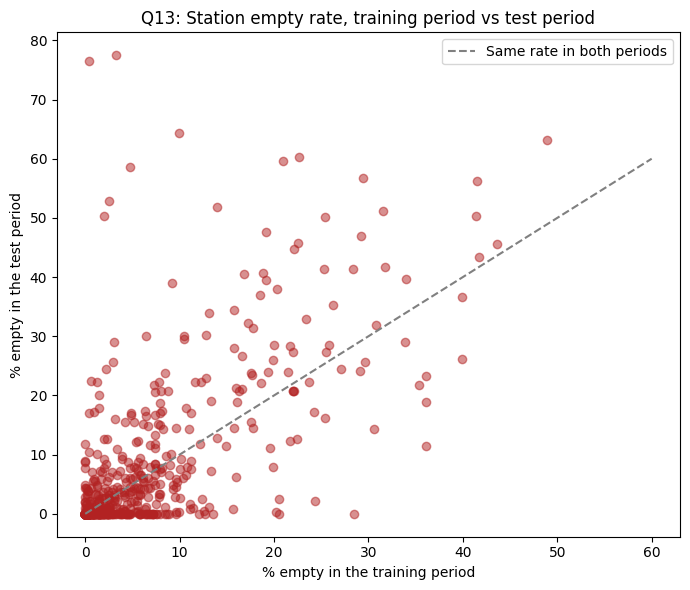

Stations compared: 624   Spearman rank correlation: 0.7
Test empty rate, 20 flagged stations: 36.7 %   all other stations: 6.2 %
Flagged stations also in the test top 20: 7 of 20


In [42]:
full_days = snaps_per_day[snaps_per_day >= 36].index
test_days = full_days[-3:]
train = gbfs[gbfs["date"] < test_days[0]]
test = gbfs[gbfs["date"].isin(test_days)]
print("Training:", train["date"].min(), "to", train["date"].max(), "  readings:", len(train))
print("Test:    ", list(test_days), " ", pd.to_datetime(list(test_days)).day_name().tolist(), "  readings:", len(test))

persist = pd.DataFrame({"train": train.groupby("name")["is_empty"].mean() * 100,
                        "test": test.groupby("name")["is_empty"].mean() * 100,
                        "train_count": train.groupby("name").size(),
                        "test_count": test.groupby("name").size()}).dropna()
persist = persist[(persist["train_count"] >= 100) & (persist["test_count"] >= 100)]

plt.figure(figsize=(7, 6))
plt.scatter(persist["train"], persist["test"], alpha=0.5, color="firebrick")
plt.plot([0, 60], [0, 60], "--", color="gray", label="Same rate in both periods")
plt.title("Q13: Station empty rate, training period vs test period")
plt.xlabel("% empty in the training period")
plt.ylabel("% empty in the test period")
plt.legend()
plt.tight_layout()
plt.show()

corr_persist = persist["train"].corr(persist["test"], method="spearman")
flagged = persist.nlargest(20, "train")
not_flagged = persist.drop(flagged.index)
test_top20 = persist.nlargest(20, "test").index
print("Stations compared:", len(persist), "  Spearman rank correlation:", round(corr_persist, 2))
print("Test empty rate, 20 flagged stations:", round(flagged["test"].mean(), 1), "%   all other stations:", round(not_flagged["test"].mean(), 1), "%")
print("Flagged stations also in the test top 20:", flagged.index.isin(test_top20).sum(), "of 20")

In [43]:
# Station-hour version: group every station-hour by its training empty rate and see how often it was empty in the test days
train_grp = train.groupby(["name", "hour"])["is_empty"]
test_grp = test.groupby(["name", "hour"])["is_empty"]
sh_split = pd.DataFrame({"train_empty_pct": train_grp.mean() * 100, "train_n": train_grp.size(),
                         "test_empty_pct": test_grp.mean() * 100, "test_n": test_grp.size()}).dropna()
sh_split = sh_split[(sh_split["train_n"] >= 8) & (sh_split["test_n"] >= 8)]

sh_split["risk_bin"] = pd.cut(sh_split["train_empty_pct"], bins=[-1, 5, 15, 30, 101],
                              labels=["under 5%", "5 to 15%", "15 to 30%", "30% or more"])
risk_table = sh_split.groupby("risk_bin", observed=True)["test_empty_pct"].agg(["mean", "size"]).round(1)
risk_table.columns = ["test_empty_pct", "station_hours"]
risk_table

,test_empty_pct,station_hours
risk_bin,,
under 5%,2.7,11146
5 to 15%,9.2,1918
15 to 30%,19.7,1064
30% or more,46.5,848


**Answer:** Yes, within the limits of a short log. We used September 16 to October 14 for training and the last three days (October 15 to 17) for testing. The rank correlation between training and testing was 0.70, so station rankings were fairly consistent. The 20 stations we flagged during training were empty 36.8% of the time during testing, compared with 6.2% for the other stations, and 7 of them were also in the test top 20.

The pattern is even clearer by station-hour. Station-hours that were empty under 5% of the time in training were empty 2.7% of the time in the test days, while those at 30% or more were empty 46.8% of the time.

**Takeaway:** Past empty rates are useful for identifying stations that may have shortages in the future. Our test covered only three days, one of them a Saturday, so this is a pattern that held once rather than proven forecast accuracy. Bluebikes could use last week's station-hour rates as next week's priority list and refresh it every week.

### Q14: The priority list (Mia)



We reuse the Q4 `flow` table (station x hour, weekdays): net flow per dock, with the live empty and full rates from the dense weekdays merged on. The 20 station-hours that lose the most bikes per dock and the 20 that gain the most are the priority list, shown in full as a table. The chart then ranks the ten windows where the most riders actually find no bike.

In [44]:
flow["net_per_dock"] = flow["net_per_day"] / flow["capacity"]
live = wd_dense.groupby(["name_key", "hour"])[["is_empty", "is_full"]].mean() * 100
live.columns = ["empty_rate", "full_rate"]
live["live_readings"] = wd_dense.groupby(["name_key", "hour"]).size()
flow14 = flow.merge(live, left_on=["name_key", "hour"], right_index=True, how="left")

ranked_dock = flow14.sort_values("net_per_dock")
bike_risk = ranked_dock.head(20).copy()
bike_risk["risk"] = "no bike"
bike_risk["riders"] = bike_risk["departures"] / num_days
dock_risk = ranked_dock.tail(20).copy()
dock_risk["risk"] = "no dock"
dock_risk["riders"] = dock_risk["arrivals"] / num_days
priority = pd.concat([bike_risk, dock_risk])
print("Priority station-hours:", len(priority), "  from", priority["name_key"].nunique(), "stations")

Priority station-hours: 40   from 25 stations


In [45]:
priority["label"] = priority["station_name"] + " " + priority["hour"].astype(str) + ":00"
priority.to_csv(OUT + "/priority_station_hours.csv", index=False)

# the full list: 20 bike-shortage and 20 dock-shortage station-hours, ranked by net bikes per dock
priority[["label", "risk", "net_per_day", "net_per_dock", "empty_rate", "full_rate", "riders"]].reset_index(drop=True).round(2)

,label,risk,net_per_day,net_per_dock,empty_rate,full_rate,riders
0,Ames St at Main St 17:00,no bike,-20.91,-1.10,6.25,10.42,26.08
1,Longwood Ave at Binney St 17:00,no bike,-12.01,-0.80,27.08,0.00,14.15
2,Ames St at Main St 16:00,no bike,-13.04,-0.69,0.00,8.89,17.74
3,Longwood Ave at Binney St 16:00,no bike,-10.12,-0.67,8.89,6.67,12.10
4,Ames St at Main St 18:00,no bike,-12.28,-0.65,56.25,0.00,16.14
5,Longwood Ave at Binney St 15:00,no bike,-6.17,-0.41,0.00,8.57,8.51
6,Old Morse Park at Putnam Ave 8:00,no bike,-5.74,-0.38,0.00,0.00,6.92
7,MIT Pacific St at Purrington St 8:00,no bike,-7.08,-0.37,11.43,0.00,12.22
8,Harvard University Housing - 115 Putnam Ave at...,no bike,-5.31,-0.35,8.57,0.00,6.18
9,Cambridge Dept. of Public Works -147 Hampshire...,no bike,-6.56,-0.35,22.86,0.00,8.24


Riders affected: departures per weekday in that hour times the share of dense weekday readings in which the station was empty (and arrivals times the share full). This ranks a station that is empty 40% of the time at 6 pm above one empty 40% of the time at 3 am. Only station-hours with at least 15 live readings are ranked, and the chart shows the top ten.

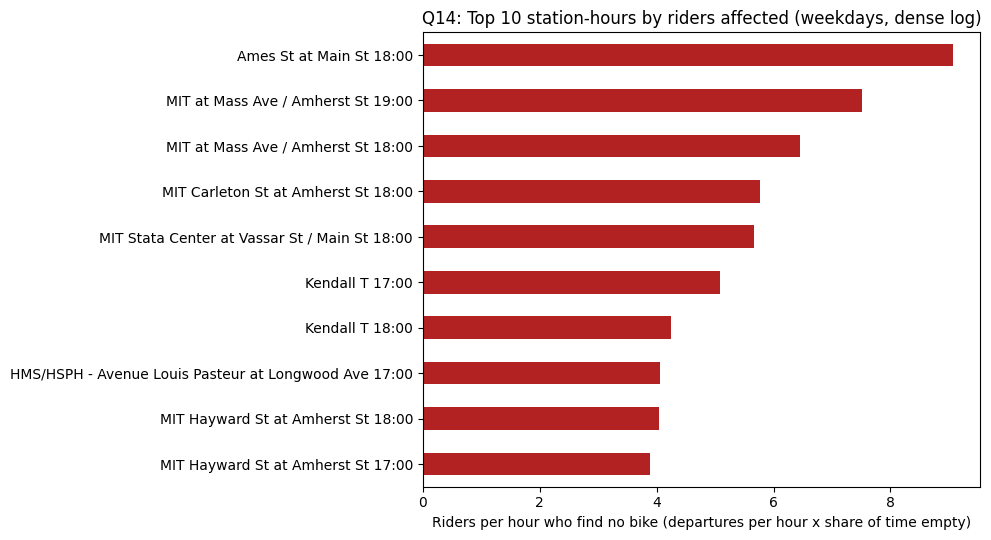

Weekday station-hours with at least 15 live readings: 14398
Riders affected per hour, top 5 windows together: 34.5
Share of the total estimated rider impact: top 15 7.1 %   top 50 15.7 %
Top 15 bike-shortage windows by riders affected:


,station_name,hour,capacity,departures_per_day,empty_rate,riders_hit_per_hour
1003,Ames St at Main St,18,19,16.1,56.2,9.1
9170,MIT at Mass Ave / Amherst St,19,31,17.1,44.0,7.5
9169,MIT at Mass Ave / Amherst St,18,31,20.7,31.2,6.5
9193,MIT Carleton St at Amherst St,18,27,7.5,77.1,5.8
9265,MIT Stata Center at Vassar St / Main St,18,35,8.8,64.6,5.7
7759,Kendall T,17,23,12.2,41.7,5.1
7760,Kendall T,18,23,8.2,52.1,4.2
7096,HMS/HSPH - Avenue Louis Pasteur at Longwood Ave,17,25,7.5,54.2,4.1
9217,MIT Hayward St at Amherst St,18,27,5.7,70.8,4.0
9216,MIT Hayward St at Amherst St,17,27,9.3,41.7,3.9


Top 5 dock-shortage windows by returns affected:


,station_name,hour,capacity,full_rate,returns_hit_per_hour
9256,MIT Stata Center at Vassar St / Main St,9,35,41.9,5.4
8683,Mass Ave at Albany St,8,18,40.0,4.3
7751,Kendall T,9,23,35.5,2.9
7476,Inman Square at Springfield St.,19,25,44.0,2.7
9185,MIT Carleton St at Amherst St,10,27,48.8,2.7


In [46]:
flow14["departures_per_day"] = flow14["departures"] / num_days
flow14["riders_hit_per_hour"] = flow14["departures_per_day"] * flow14["empty_rate"] / 100
flow14["returns_hit_per_hour"] = flow14["arrivals"] / num_days * flow14["full_rate"] / 100
ranked = flow14[flow14["live_readings"] >= 15].sort_values("riders_hit_per_hour", ascending=False)

# the 10 station-hours where the most riders find no bike
top10 = ranked.head(10).copy()
top10["label"] = top10["station_name"] + " " + top10["hour"].astype(str) + ":00"
top10.set_index("label")["riders_hit_per_hour"].sort_values().plot(kind="barh", figsize=(10, 5.5), color="firebrick")
plt.xlabel("Riders per hour who find no bike (departures per hour x share of time empty)")
plt.ylabel("")
plt.title("Q14: Top 10 station-hours by riders affected (weekdays, dense log)")
plt.tight_layout()
plt.show()

total_hit = ranked["riders_hit_per_hour"].sum()
print("Weekday station-hours with at least 15 live readings:", len(ranked))
print("Riders affected per hour, top 5 windows together:", round(ranked["riders_hit_per_hour"].head(5).sum(), 1))
print("Share of the total estimated rider impact: top 15", round(ranked["riders_hit_per_hour"].head(15).sum() / total_hit * 100, 1), "%   top 50", round(ranked["riders_hit_per_hour"].head(50).sum() / total_hit * 100, 1), "%")
print("Top 15 bike-shortage windows by riders affected:")
display(ranked[["station_name", "hour", "capacity", "departures_per_day", "empty_rate", "riders_hit_per_hour"]].head(15).round(1))
print("Top 5 dock-shortage windows by returns affected:")
display(ranked.nlargest(5, "returns_hit_per_hour")[["station_name", "hour", "capacity", "full_rate", "returns_hit_per_hour"]].round(1))

**Answer:** The 40 riskiest station-hours from the trip flows come from only 25 stations. The worst is Ames St at Main St at 5 pm: it loses 20.9 bikes per weekday, more than its 19 docks, and by 6 pm it is empty 56% of the time in the dense log. The same station is also the most full at 9 am, because people ride in to work in the morning and ride out in the evening. Bike shortages come in two kinds of places: office and hospital areas (Kendall, Longwood) in the evening, and housing areas (Putnam Ave, Harvard housing) at 8 am.

Weighting by riders changes the order but not the message. The chart shows the ten windows where the most riders find no bike, and all of them are Kendall, MIT and Longwood stations between 4 and 8 pm: Ames St at Main St at 6 pm (about 16 riders an hour, empty 56%, 9.1 riders affected per hour), MIT at Mass Ave / Amherst St at 6 and 7 pm, MIT Carleton St at 6 pm (empty 77%), MIT Stata Center at 6 pm (empty 65%) and Kendall T at 5 and 6 pm. The top 5 windows together affect about 35 riders an hour. Of the 14,398 weekday station-hours with at least 15 live readings, the top 15 carry 7.1% of the total estimated impact and the top 50 carry 15.7%, so the problem is spread over many windows but the first van loop has a clear target. The pickup list is the morning mirror image: MIT Stata Center at 9 am (full 42%, about 13 arrivals an hour) and Mass Ave at Albany St at 8 am.

**Takeaway:** Bluebikes can use this list as a daily schedule, for example move extra bikes out of Ames St after the 9 am rush and bring them back before 4 pm.

### Q15: Pair each drainer with its nearest filler (Grace)

The 15 stations with the largest weekday morning losses (7 to 9 am) are paired with the nearest of the 60 strongest morning fillers, using the straight-line distance between their coordinates.

In [47]:
from math import radians, sin, cos, asin, sqrt

# straight-line distance in km between two points on the earth (Haversine formula)
def km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = radians(lat1), radians(lon1), radians(lat2), radians(lon2)
    a = sin((lat2 - lat1) / 2) ** 2 + cos(lat1) * cos(lat2) * sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * asin(sqrt(a))

drainers = am_drain.nsmallest(15).rename("bikes_lost_per_weekday")
fillers = am_drain.nlargest(60).rename("bikes_gained_per_weekday")
drainer_info = station_lookup[["station_name", "lat", "lng"]].join(drainers, how="inner")
filler_info = station_lookup[["station_name", "lat", "lng"]].join(fillers, how="inner")
print("Drainers with coordinates:", len(drainer_info), "of 15   fillers with coordinates:", len(filler_info), "of 60")

Drainers with coordinates: 15 of 15   fillers with coordinates: 60 of 60


In [48]:
# For each drainer, find the nearest filler
pairs = []
for d_key, d_row in drainer_info.iterrows():
    best_key = None
    best_km = 999
    for f_key, f_row in filler_info.iterrows():
        dist = km(d_row["lat"], d_row["lng"], f_row["lat"], f_row["lng"])
        if dist < best_km:
            best_km = dist
            best_key = f_key
    pairs.append({"drainer_key": d_key, "drainer": d_row["station_name"], "bikes_lost_per_weekday": -d_row["bikes_lost_per_weekday"],
                  "filler_key": best_key, "filler": filler_info.loc[best_key, "station_name"],
                  "bikes_gained_per_weekday": filler_info.loc[best_key, "bikes_gained_per_weekday"], "distance_km": best_km})
pairs_df = pd.DataFrame(pairs).sort_values("distance_km").reset_index(drop=True)

print("Median distance:", round(pairs_df["distance_km"].median(), 2), "km   longest:", round(pairs_df["distance_km"].max(), 2), "km   filler stations used:", pairs_df["filler_key"].nunique())
pairs_df[["drainer", "bikes_lost_per_weekday", "filler", "bikes_gained_per_weekday", "distance_km"]].round(2)

Median distance: 0.85 km   longest: 1.22 km   filler stations used: 9


,drainer,bikes_lost_per_weekday,filler,bikes_gained_per_weekday,distance_km
0,Kennedy-Longfellow School 158 Spring St,11.28,325 Binney St.,7.92,0.37
1,MIT Pacific St at Purrington St,11.68,Mass Ave at Albany St,10.95,0.43
2,Berkshire Street at Cambridge Street,10.31,325 Binney St.,7.92,0.55
3,MIT Vassar St,29.96,Commonwealth Ave at Granby St,8.01,0.64
4,Lewis Wharf at Atlantic Ave,9.12,Surface Rd at India St,7.17,0.64
5,Sennott Park Broadway at Norfolk Street,10.05,One Kendall Square at Hampshire St / Portland St,9.16,0.68
6,Cambridge Dept. of Public Works -147 Hampshire...,12.01,One Kendall Square at Hampshire St / Portland St,9.16,0.73
7,955 Mass Ave,9.62,Harvard Square at Mass Ave/ Dunster,9.00,0.85
8,Nashua Street at Red Auerbach Way,11.38,Boston City Hall - 28 State St,13.76,0.93
9,Dana Park,11.45,Mass Ave at Albany St,10.95,0.94


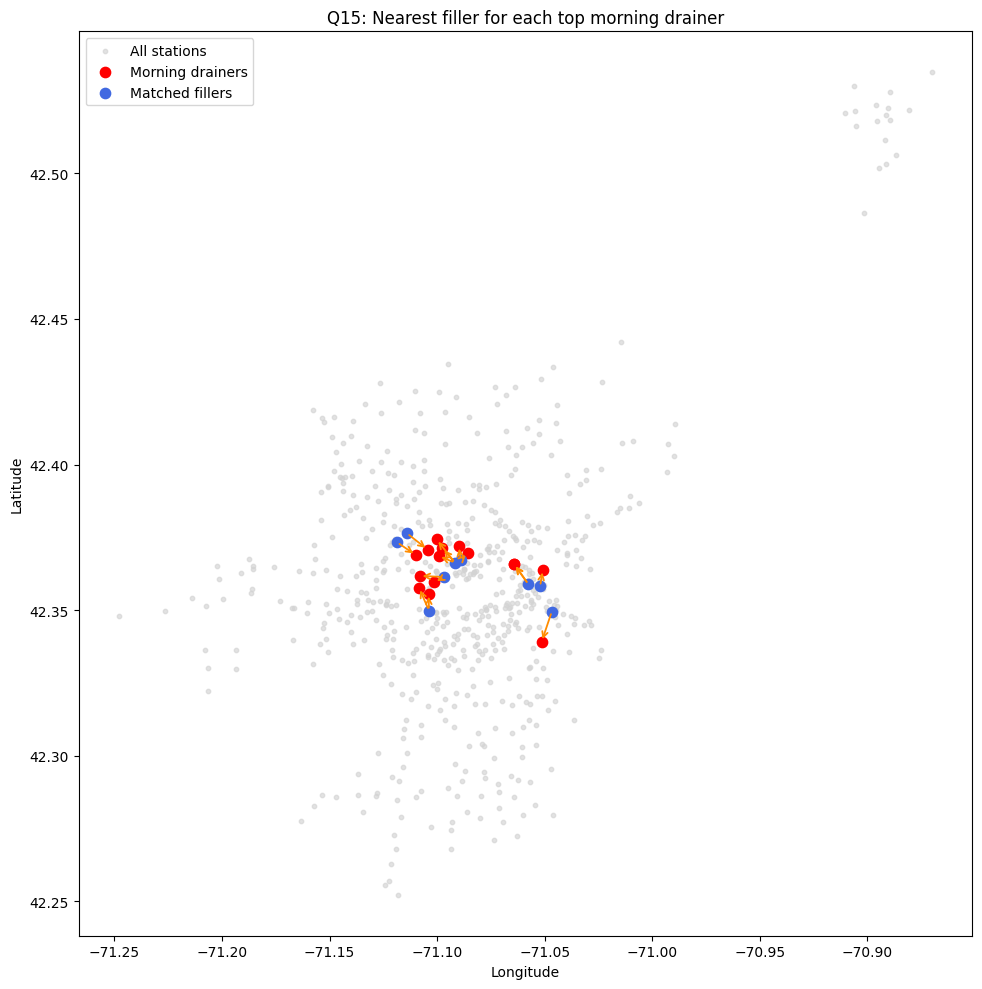

In [49]:
plt.figure(figsize=(11, 10))
plt.scatter(stations["lng"], stations["lat"], s=10, color="lightgrey", alpha=0.65, label="All stations")
plt.scatter(drainer_info["lng"], drainer_info["lat"], s=55, color="red", label="Morning drainers")
chosen = filler_info.loc[pairs_df["filler_key"].unique()]
plt.scatter(chosen["lng"], chosen["lat"], s=55, color="royalblue", label="Matched fillers")
for i in range(len(pairs_df)):
    f_row = filler_info.loc[pairs_df.loc[i, "filler_key"]]
    d_row = drainer_info.loc[pairs_df.loc[i, "drainer_key"]]
    plt.annotate("", xy=(d_row["lng"], d_row["lat"]), xytext=(f_row["lng"], f_row["lat"]),
                 arrowprops=dict(arrowstyle="->", color="darkorange", lw=1.3))
plt.title("Q15: Nearest filler for each top morning drainer")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.gca().set_aspect(1 / np.cos(np.radians(stations["lat"].mean())))
plt.tight_layout()
plt.show()

**Answer:** The pairs are close together: the median distance is 0.85 km, the longest is 1.22 km, and only 9 different filler stations are needed. MIT Vassar St, the biggest drainer (30 bikes a morning), pairs with Commonwealth Ave at Granby St 0.64 km away. Short van loops between these pairs could move bikes from fillers to drainers before the morning rush. Historical net arrivals do not guarantee that spare bikes are available at a particular time, the method does not optimise van routes, and a filler can be assigned to more than one drainer.

**Takeaway:** All 15 major morning draining stations have potential filler partners within 1.22 km, with a median straight-line distance of just 0.85 km. This suggests that Bluebikes could use short, targeted rebalancing routes to move bikes from stations gaining bikes to those losing bikes during morning commuting hours. However, these are potential pairings based on geographic proximity and historical net flow, not confirmed operational routes.

## 6. Conclusion

Our analysis shows that Bluebikes shortages are concentrated in specific stations and hours, and that historical patterns can help identify them. Across the 31-file live log, 6.1% of station readings were empty and 4.8% full. The 20 worst stations accounted for 19.5% of all empty readings (Q11). Shortages were especially common around Kendall, MIT and downtown, and weekday stations were more often empty during the evening rush (5.7%) than the morning rush (4.4%) (Q8–Q9).

Trip patterns were consistent: 18 of the top 20 drainers and fillers repeated across both halves of the year (Q5), and the biggest drainers lost bikes in 98–100% of weeks (Q6). The live data also showed some predictability. The 20 stations flagged using earlier readings were empty 36.8% of the time during the three test days, compared with 6.2% for other stations, with a rank correlation of 0.70 (Q13).

However, trip history alone does not reliably identify actual shortages. The biggest morning drainers were empty 1.59 times as often as average, but the individual station rankings barely agreed (Spearman = −0.14, Q12). Our estimated 80 refills and 69 pickups per day suggest that rebalancing may be influencing these patterns (Q10). **Trip history shows where bikes are being lost; live availability shows where riders actually face shortages.**

### Evaluation against our success metrics

| Metric | Target | Result | Status |
|---|---|---|---|
| M1: Consistency | ≥15/20 overlap; r ≥ 0.8 | 18/20 drainers and fillers repeated; r = 0.97 | Met |
| M2: Real-world agreement | k ≥ 1.5; Spearman ≤ −0.3 | k = 1.59; Spearman = −0.14 | Partly met |
| M3: Predictability | Spearman ≥ 0.5; flagged ≥ 3× | Spearman = 0.70; flagged stations 5.9× more often empty | Met (3-day test) |
| M4: Data coverage | ≥5 days with ≥36 snapshots, all hours | 11 dense days; every hour covered (min. 31 weekday / 12 weekend snapshots) | Met |
| M5: Actionability | 40 station-hours, ≤30 stations, median < 1.5 km | 40 station-hours across 25 stations; median pairing distance 0.85 km | Met |

We met four of five targets and partly met M2. Whether our recommendations actually reduce shortages requires a real-world pilot.

### 6.1 Challenges

Trip history records completed rides, not whether stations were empty or full. Since the GBFS feed only provides current availability, we built our own logger. It initially captured too few readings, so we improved its schedule on October 7 and used the following 11 dense days for hourly analysis.

Combining datasets was also difficult. Trip station IDs did not match the GBFS station list, so we joined using cleaned station names, matching 98.71% of trips. We also cleaned missing stations, duplicates and invalid durations, and filtered the weather data to Boston Logan Airport. Finally, without actual van records, we had to estimate rebalancing from sudden changes in bike counts.

### 6.2 Risks and Limitations

- **Short live-data window:** The 11 dense days cover October only, not the summer peak. Our prediction test covers just three days (October 15–17), including a Saturday, so the results are encouraging but not proven long-term forecasts.
- **Van activity is estimated:** Sudden bike-count changes may indicate van visits, but could also reflect rider activity. Our approximately 80 refills per day are an estimate, not confirmed van movements.
- **Unobserved demand:** Trip data only records successful rides. Riders who cannot find a bike leave no trip record, so our estimates of riders potentially affected by shortages are not observed failed rentals.
- **Other influences:** Weather, holidays, events and operational changes can affect shortages. Our findings show associations, not proof of causation.

### 6.3 Recommendations

Bluebikes should focus rebalancing on the stations and hours with the greatest demonstrated shortage risk.

1. **Add an evening delivery loop around Kendall, MIT and Longwood.** The ten highest-impact station-hours are in these areas between 4 and 8 pm. Prioritize Ames St at Main St around 6 pm, when it was empty 56% of the time and an estimated nine riders per hour could be affected (Q14).

2. **Clear full docks during the morning rush.** Prioritize stations such as MIT Stata Center and Mass Ave at Albany St, where high full rates suggest that pickups could improve dock availability (Q14).

3. **Use short morning rebalancing routes.** All 15 major morning drainers have a potential filler station within 1.22 km, with a median pairing distance of 0.85 km (Q15). Use these pairings as starting points, while checking actual bike availability before dispatching vans.

4. **Update priorities using the live feed.** Refresh station-hour shortage rankings weekly, combining historical trip patterns with recent availability rather than relying on trip volume alone (Q12–Q13).

**Next steps:** Pilot the evening loop and measure changes in shortage rates, repeat the prediction test over more weekdays and seasons, and compare our estimated van movements with actual operational records.

Overall, the goal is to move Bluebikes from broad rebalancing coverage toward targeted action at the stations and hours where shortages are most likely.

### Evaluation against success metrics

| Metric | Result | Status |
|---|---|---|
| M1: Consistent patterns | 18/20 drainers and fillers repeated; r = 0.97 | Met |
| M2: Trips vs live data | k = 1.59; rank correlation = −0.14 | Partly met |
| M3: Predictability | r = 0.70; flagged stations 5.9× more often empty | Met (3-day test) |
| M4: Data coverage | 11 dense days; all hours covered | Met |
| M5: Priority list | 40 station-hours across 25 stations; median pair distance 0.85 km | Met |
| M6: Reduced shortages | Not tested yet | Cannot evaluate |

**Overall:** Four metrics were met, one was partly met, and one cannot be evaluated yet. Trip history identifies potential shortages, but live availability gives a better picture of which stations need attention.

### Success metrics: Did we meet our goals?

| Metric | Result | Status |
|---|---|---|
| **M1: Consistent patterns** | 18/20 drainers and fillers repeated; r = 0.97 | Met |
| **M2: Agreement with live data** | k = 1.59, but rank correlation = −0.14 | Partly met |
| **M3: Predictability** | r = 0.70; flagged stations were about 6 times more often empty | Met (3-day test) |
| **M4: Data coverage** | 11 dense days, with readings across all hours | Met |
| **M5: Actionable recommendations** | 40 station-hours across 25 stations; median pairing distance 0.85 km | Met |
| **M6: Reduced shortages** | No intervention has been tested yet | Not yet measured |

We met four targets, partly met one, and could not evaluate the last. The main finding is that historical trips help identify stations under pressure, but live availability data is needed to see where shortages actually happen.

### Recommended actions for Bluebikes

1. **Prioritize evening deliveries in Kendall, MIT, and Longwood.** Start with Ames St at Main St around 6 PM, when it was empty in 56% of readings (Q14).
2. **Pick up bikes from frequently full stations.** Focus on stations such as Blue Hill Ave at Almont St and Truman Parkway, where riders may struggle to find open docks (Q11).
3. **Use short morning rebalancing loops.** All 15 major morning drainers have potential filler partners within 1.22 km (Q15).
4. **Update priorities weekly.** Use the live station-hour empty rates rather than relying only on historical trips (Q12–Q14).

### Next steps

1. Repeat the Q13 test with new weekday data.
2. Compare estimated van visits with actual Bluebikes rebalancing records.
3. Test whether station-hour empty rates can predict shortages in the next hour.

## 7. Challenges

| Challenge | How we handled it |
|---|---|
| **Different station IDs** | The three datasets used different station IDs, so we matched stations by cleaned names (98.7% match) and used the GBFS feed for station information. |
| **Trips don't show availability** | Trip data only shows arrivals and departures. We collected live GBFS readings to measure actual empty and full stations. |
| **Limited live data** | The logger initially collected too few readings. We improved it on October 7 and used only the 11 dense days for hourly analysis. |
| **Data cleaning** | Removed duplicate readings and trips with invalid durations or missing stations. We also filtered the weather data to Boston Logan. |
| **Short test period** | Q13 used only three test days, so we treated the results as early evidence rather than proof of long-term reliability. |
| **No van records** | We estimated possible rebalancing visits from sudden changes in bike counts, but these are not confirmed van movements. |

The biggest limitation is the short period of frequent live readings. More weeks of data and actual van records would help us test whether our recommendations work consistently.

## References
- Bluebikes System Data: https://bluebikes.com/system-data
- Bluebikes Data License Agreement: https://bluebikes.com/data-license-agreement
- Bluebikes trip history (S3): https://s3.amazonaws.com/hubway-data/index.html
- Bluebikes GBFS feed: https://gbfs.bluebikes.com/gbfs/gbfs.json
- General Bikeshare Feed Specification (MobilityData): https://github.com/MobilityData/gbfs
- NOAA Climate Data Online, GHCN-Daily, station USW00014739: https://www.ncei.noaa.gov/cdo-web/
- Team logger repository: https://github.com/AdhamKhouly/bluebikes-logger
- pandas, NumPy, Matplotlib documentation: https://pandas.pydata.org/docs/, https://numpy.org/doc/, https://matplotlib.org/stable/

## Generative AI Disclosure

We used generative AI tools in the following ways.

- **Data collection code.** Claude (Anthropic) drafted the GitHub Actions logging script that collects the GBFS snapshots and the cell that copies the log files into our Google Drive folder. We deployed the logger, monitored it, and fixed the schedule when it was running too rarely.
- **Coding and debugging.** Claude, used in the Claude Code tool, helped write and debug the cleaning and station-matching code, and wrote the first version of the Section 4 and Section 5 code (Q8 to Q15, including the train/test split and the riders-affected ranking) from our task outline. ChatGPT was used for syntax questions and for checking Markdown and chart code.
- **Writing.** Claude drafted the data dictionary, the success metrics table and first versions of some answer paragraphs, and then shortened and simplified the notebook after our own edits. ChatGPT and Grammarly were used to polish wording. We rewrote the Executive Summary, the answers and the conclusion so they match the numbers printed in the notebook.
- **Grammarly** was used to polish certain sections of the text.
- **Other.** ChatGPT generated the opening image. Canva was used to build the presentation slides.

The team ran all the code on our data in Google Colab, compared the printed outputs with the text, and is responsible for the cleaning decisions, the interpretation of the results and the recommendations. The Team Assignment finding that the biggest drainers were not more often empty was what the data showed, and it is what led us to find the logger problem.
